# Credit Card Fraud Detection - Classfication binaire project

### Objective =>
* Build a model to detect whether a credit card transaction is fraudulent (1) or legitimate (0).
* This is a highly imbalanced binary classification problem.

### Importation Librairies 

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

# Set option to display all columns
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### EDA (exploration analyse data)
#### Analyse de Forme :
* identify target => Class (1-0) {Classification binaire}
* num of ligne & colonne => (lignes/exemple=284807, colonnes=31) /pour colonne on a Time-V1/V28-Amount-Class
* type des variables(features) => Numeriques (30 float+ 1 int)
* identifiant Nan (missing values) => No Nan ! YAY :)

  
#### Analyse de Forme :
* Visualisation de target =>
#we have => 492(fraude=1) / 284315(not-fraude=0) # rare to detect fraude(special case)
#majority to values is 0(not-fraude) and rare for predicting a 1(fraude)

* Comprehension des diff var (seperatly) =>
#time to detect Fraude(1) take less a little than Notfraude(0)
#amount is btw (0-8000) => problem it has bigger echelle n data just compress in small echelle
#most of V values in negative range (-20 - 5) and some in positive range(0-20)

* Visualisation des relations entre features with target and with each others =>
#time to detect Fraude(1) take less a little than Notfraude(0)
#all values of V detect the case of fraude(1) if they're zero means Nofraude(1)
#for the amout of Fraude(1) coss more than the NotFraude(0) - [logical since its scamming they ask for more]
  
* Identification des outliers =>
#we see a lot of outliers espacially in V colomns in the case of NotFraude(0)
#outliers they're alot 39163(most values in colonne V27)

* Elimine some columns that arent important like: #elimine non inmportant features with alot of outliers['V1','V3', 'V5', 'V6', 'V7','V9', 'V10','V12', 'V14', 'V16', 'V17', 'V18']

#### Explication des Colonnes 
##### Time
* Nombre de secondes depuis la première transaction du dataset
* Exemple: 0 = première transaction, 3600 = 1 heure après

##### V1 à V28
* Numéros 1 à 28 d'un système de chiffrage
* La banque a caché les vrais noms pour protéger la confidentialité
* Ce sont des mesures techniques du paiement (anonymisées)

##### Amount
* Montant de l'achat en euros
* Exemple: 149.62 = achat de 149,62€

##### Class
* 0 = achat normal (pas une fraude)
* 1 = achat frauduleux (fraude)

=> pour quoi on a plusieurs valeurs de V :(Pourquoi pas un seul colonne?)
Parce qu'une fraude est complexe:
* Un achat à l'étranger n'est PAS toujours une fraude (tu voyages)
* Un gros achat n'est PAS toujours une fraude (tu achètes une TV)
* Une heure tardive n'est PAS toujours une fraude (tu fais des courses nocturnes)
* Mais combiner plusieurs signaux → meilleure détection!


In [3]:
df.shape

(284807, 31)

In [4]:
df.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,-0.371407,1.341262,0.359894,-0.358091,-0.137134,0.517617,0.401726,-0.058133,0.068653,-0.033194,0.084968,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,-0.099254,-1.416907,-0.153826,-0.751063,0.167372,0.050144,-0.443587,0.002821,-0.611987,-0.045575,-0.219633,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,1.249376,-0.619468,0.291474,1.757964,-1.323865,0.686133,-0.076127,-1.222127,-0.358222,0.324505,-0.156742,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,-0.410430,-0.705117,-0.110452,-0.286254,0.074355,-0.328783,-0.210077,-0.499768,0.118765,0.570328,0.052736,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,-0.366846,1.017614,0.836390,1.006844,-0.443523,0.150219,0.739453,-0.540980,0.476677,0.451773,0.203711,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [5]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [6]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


C:\Users\hp\AppData\Local\Temp\ipykernel_7988\3691513984.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df , palette='Set2')


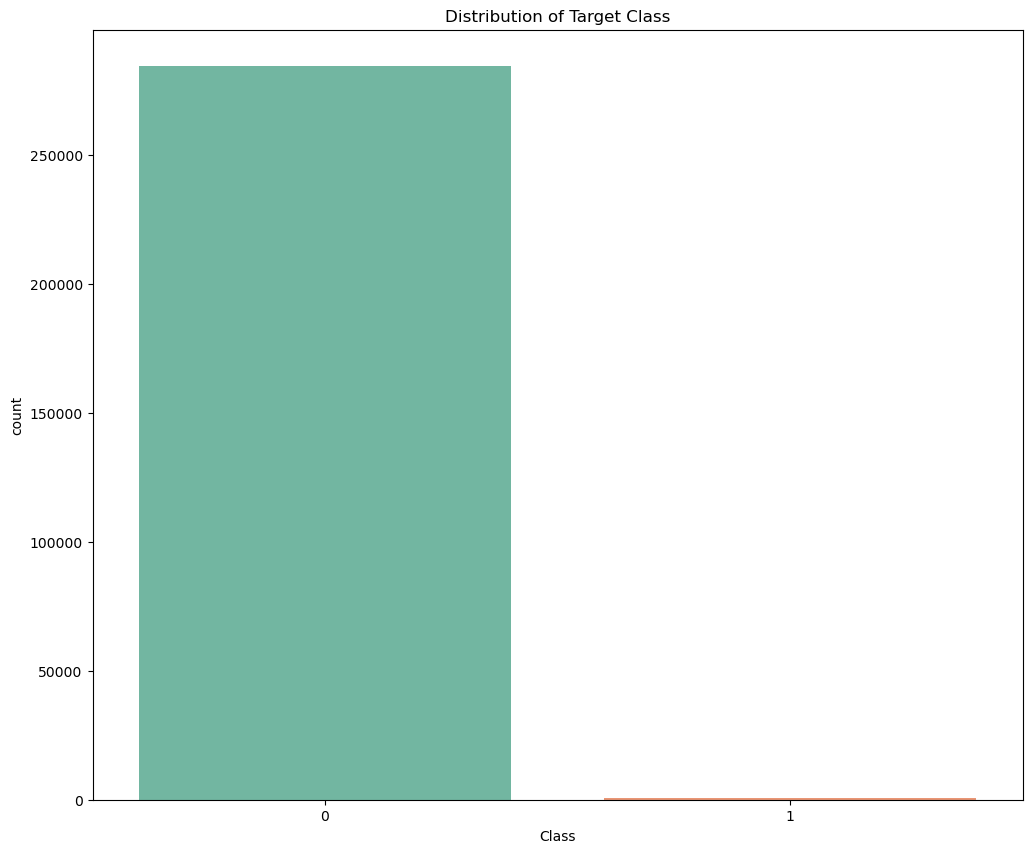

In [9]:
# shows how many samples belong to each class (0 vs 1).
plt.figure(figsize=(12,10))
sns.countplot(x='Class', data=df , palette='Set2')
plt.title('Distribution of Target Class')
plt.show()
# majority to values is 0(not-fraude) and rare for predicting a 1(fraude)

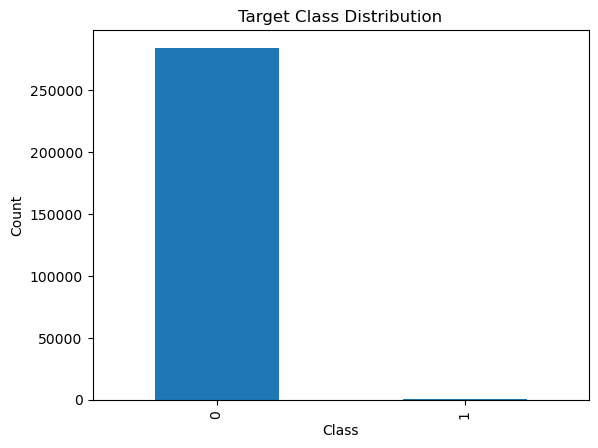

In [10]:
df['Class'].value_counts().plot(kind='bar')
plt.title("Target Class Distribution") 
plt.xlabel("Class") 
plt.ylabel("Count") 
plt.show()

In [11]:
dist_target = df['Class'].value_counts()
print(dist_target)
# we have => 492(fraude=1) / 284315(not-fraude=0) # rare to detect fraude(special case)

Class
0    284315
1       492
Name: count, dtype: int64


In [12]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

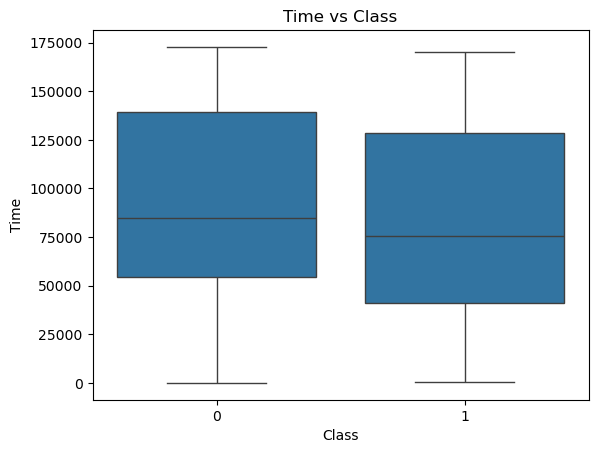

In [13]:
sns.boxplot(x="Class", y="Time", data=df) 
plt.title("Time vs Class") 
plt.show()

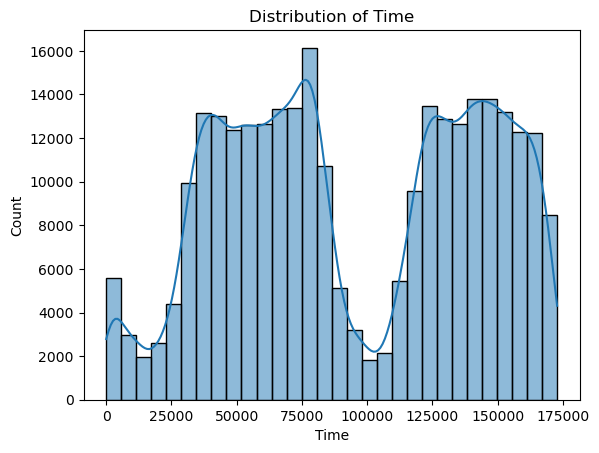

In [14]:
sns.histplot(df['Time'], bins=30, kde=True) 
plt.title("Distribution of Time")
plt.show()

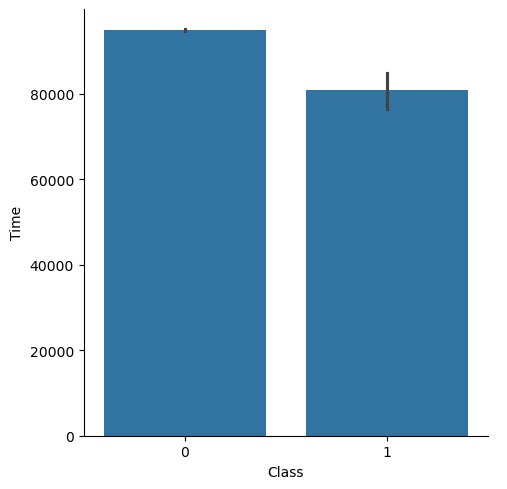

In [15]:
sns.catplot(x='Class' , y='Time' , data=df , kind='bar') #time to detect Fraude(1) take less a little than Notfraude(0)

Text(0, 0.5, 'Frequency')

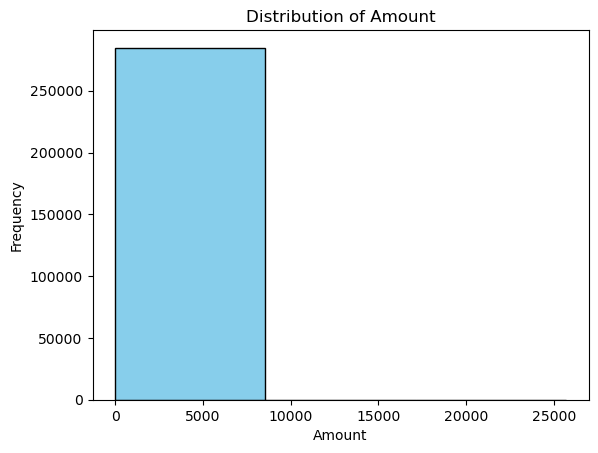

In [16]:
plt.hist(df['Amount'], bins=3, color='skyblue', edgecolor='black') 
plt.title("Distribution of Amount") 
plt.xlabel("Amount")
plt.ylabel("Frequency") #amount is btw (0-8000) => problem it has bigger echelle n data just compress in small echelle

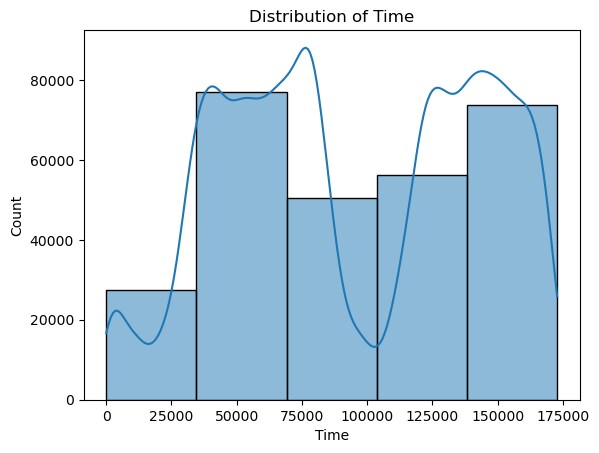

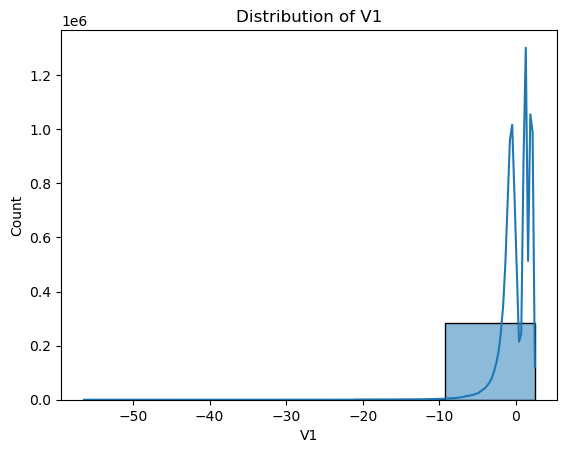

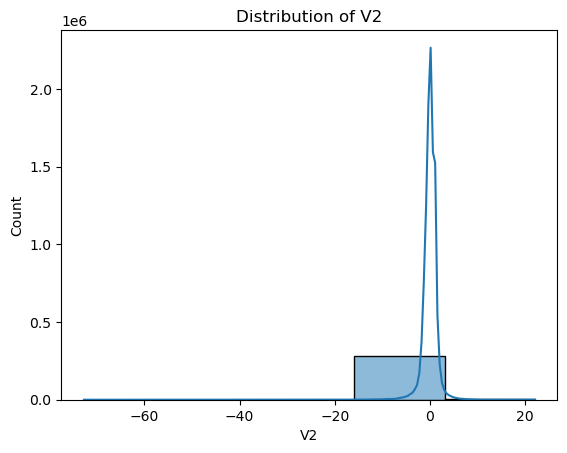

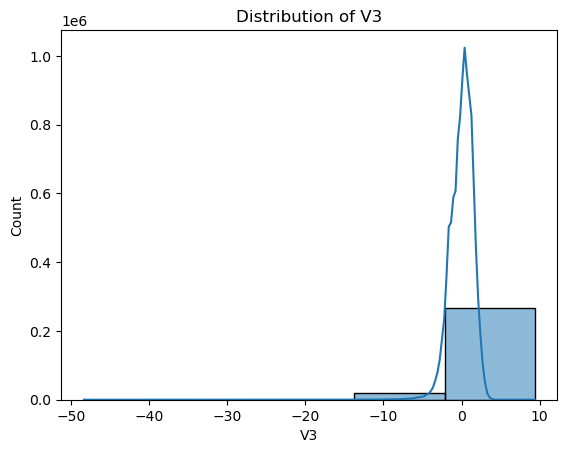

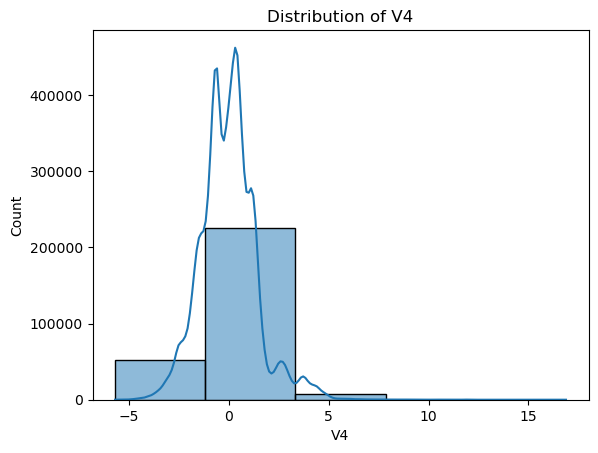

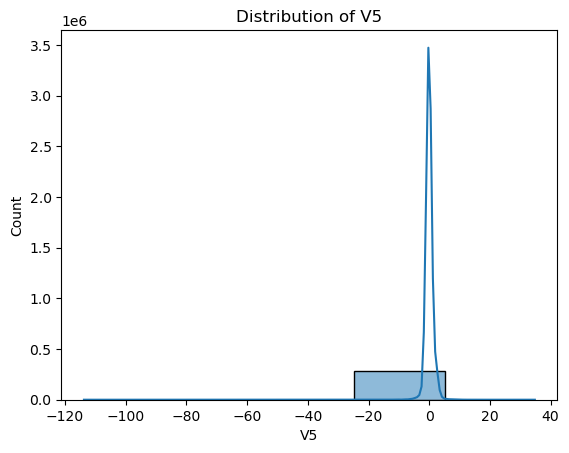

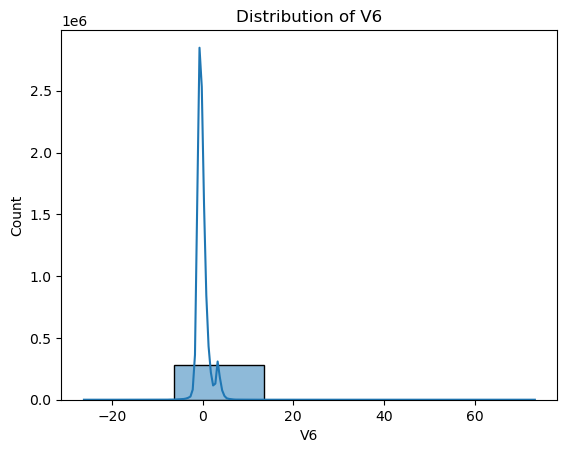

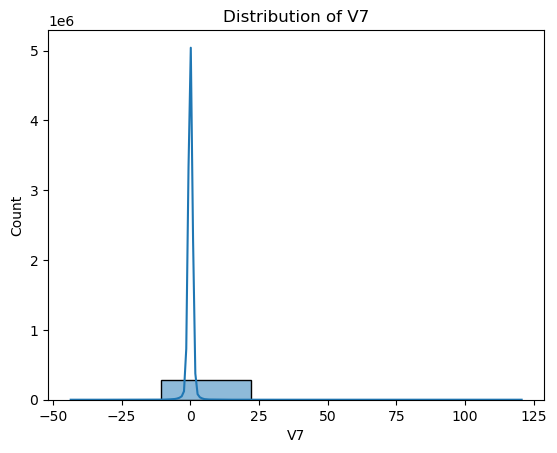

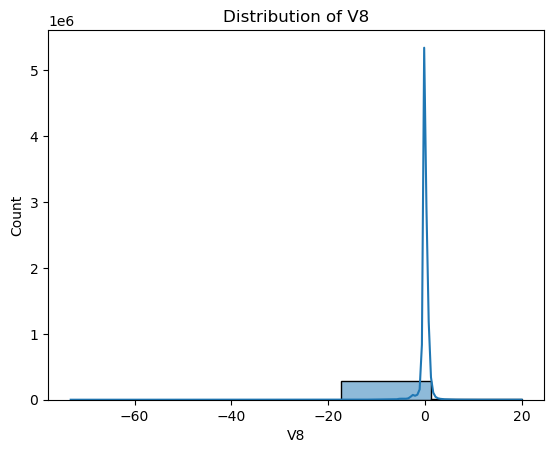

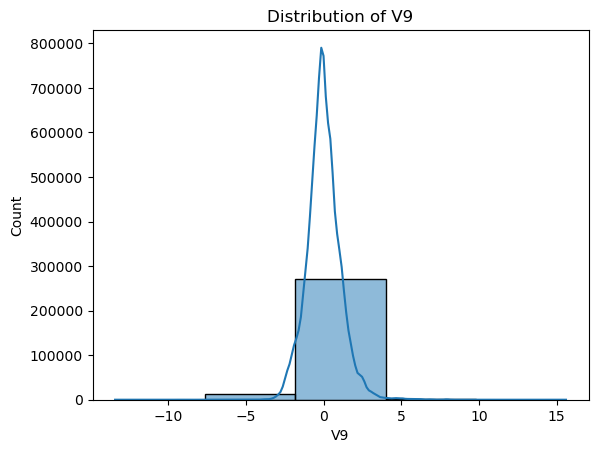

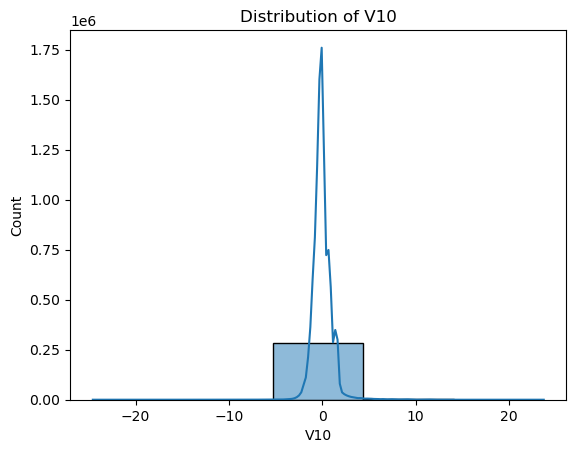

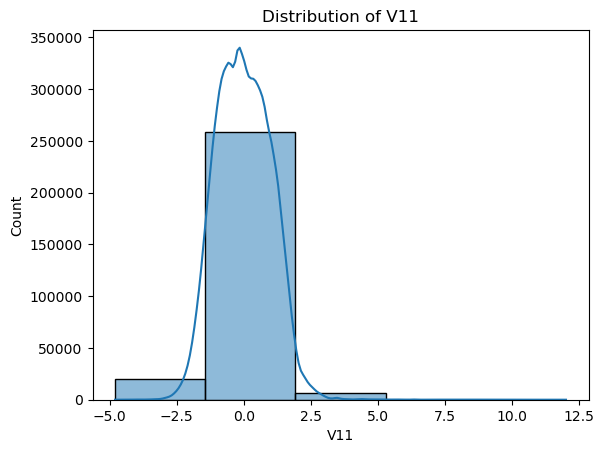

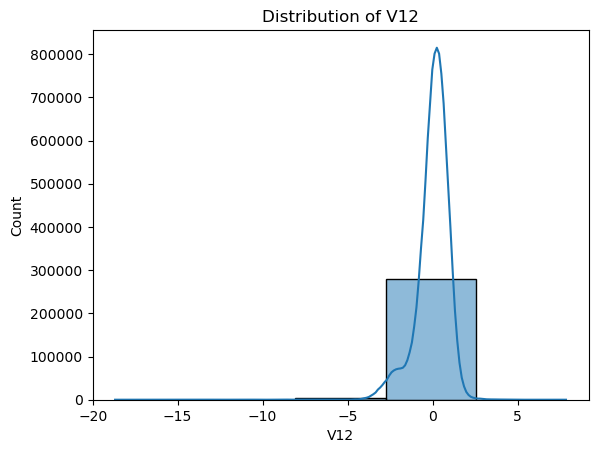

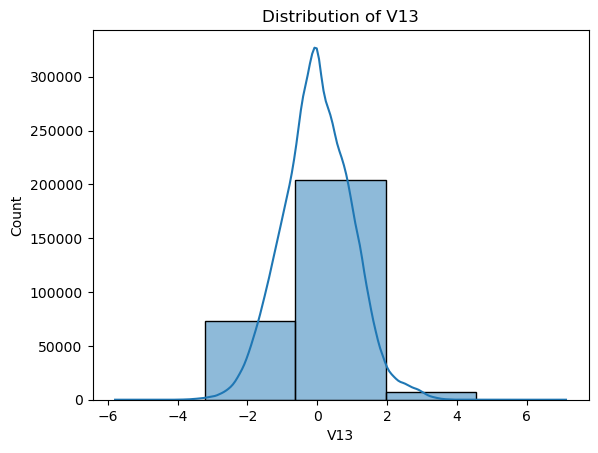

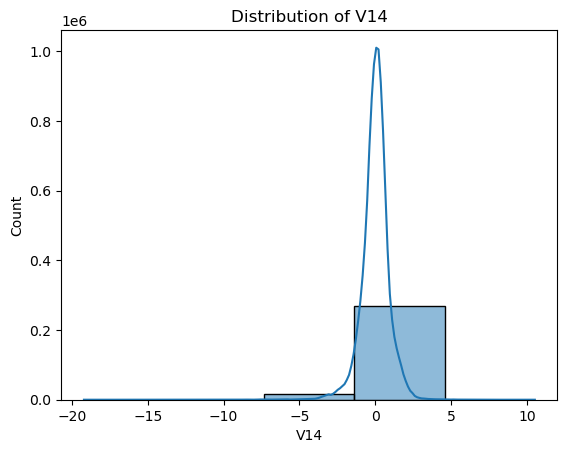

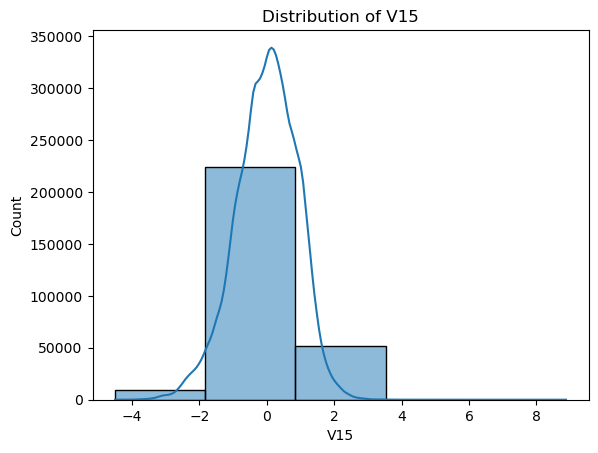

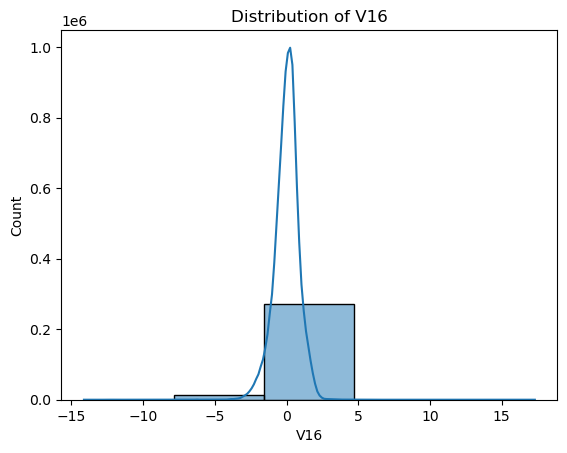

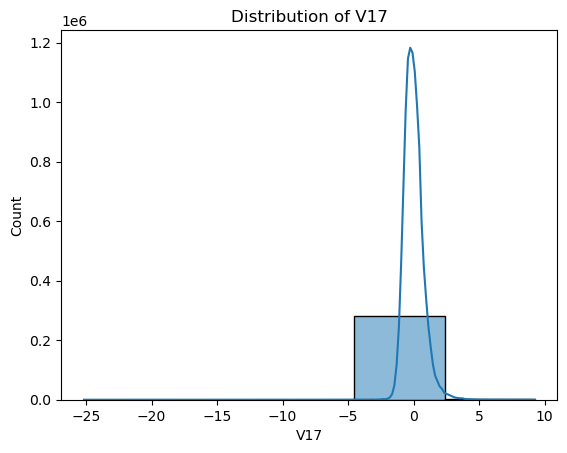

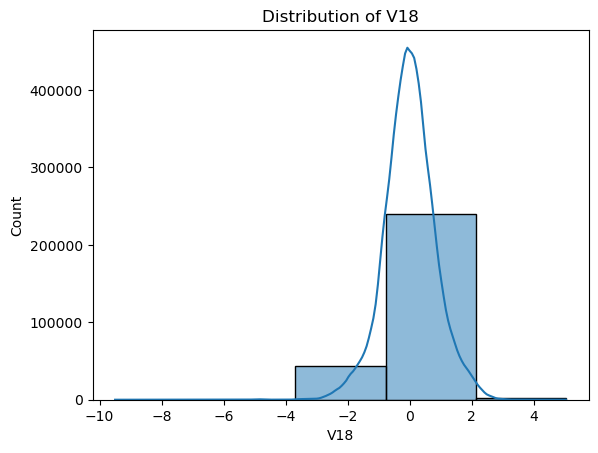

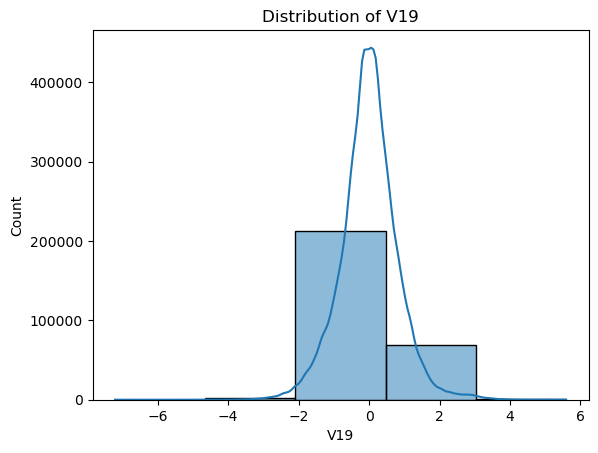

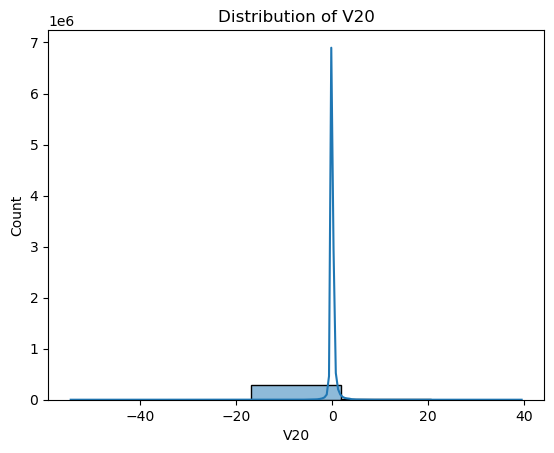

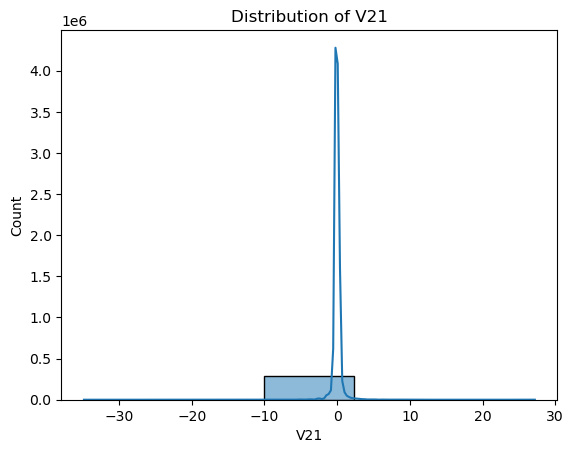

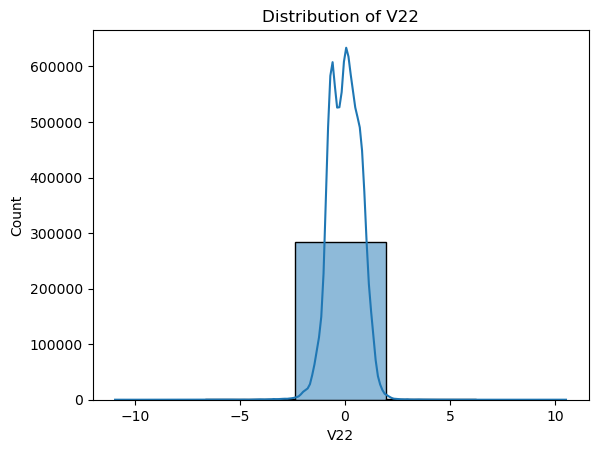

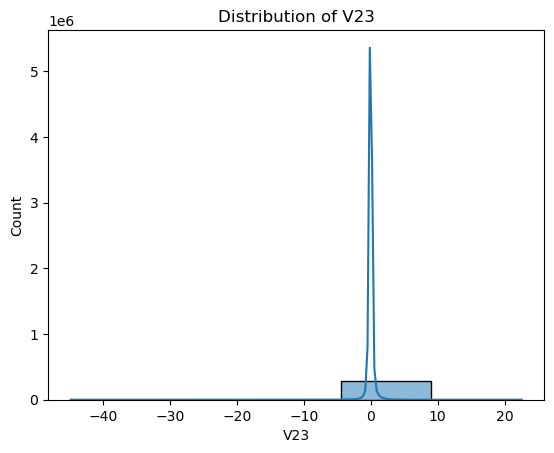

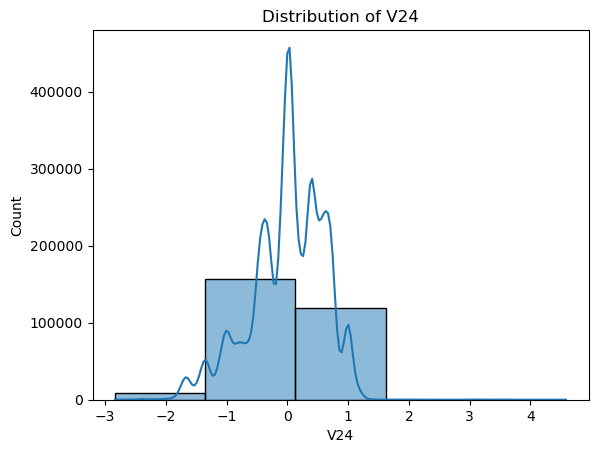

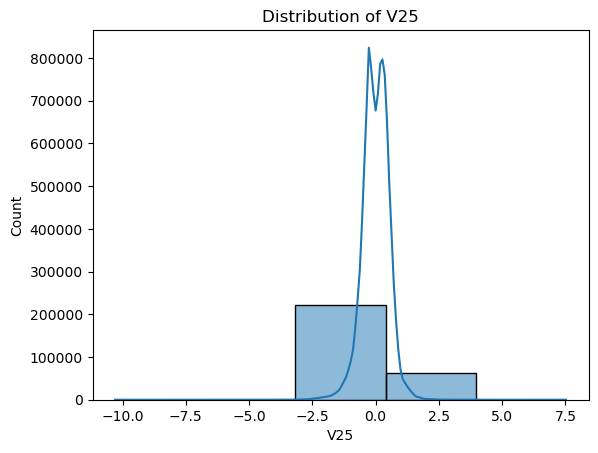

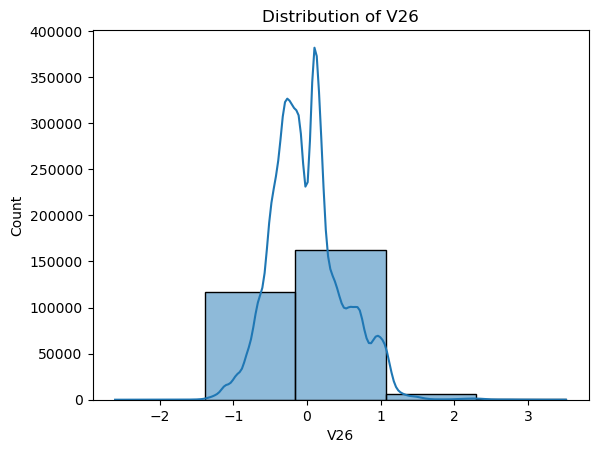

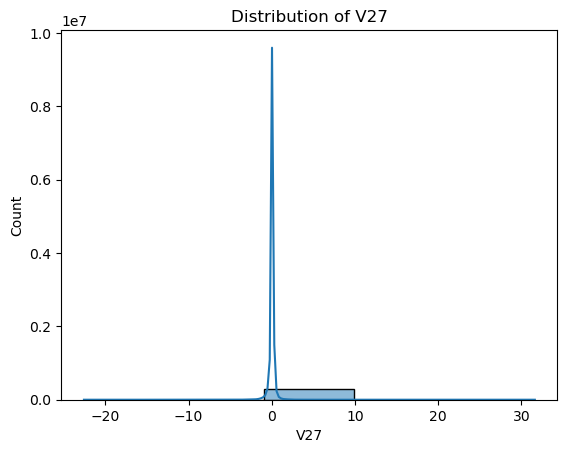

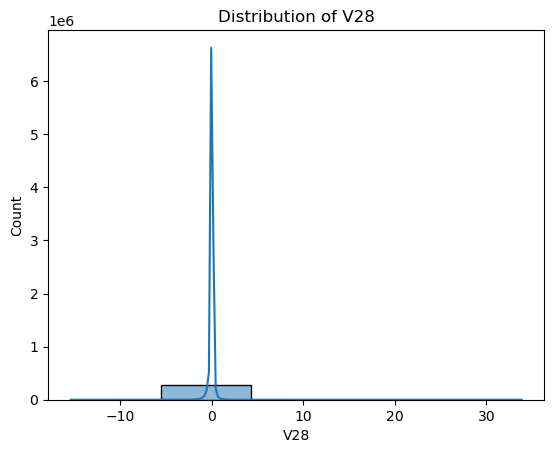

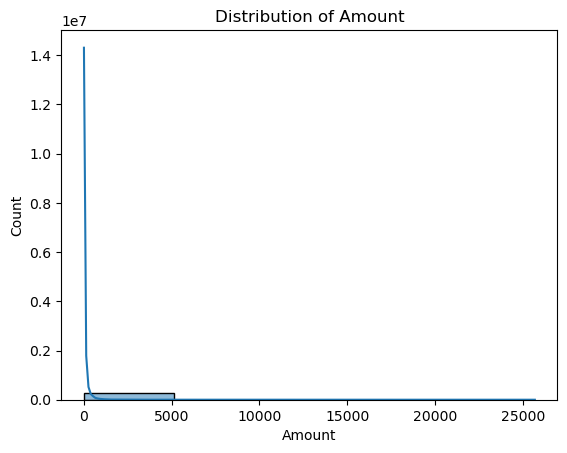

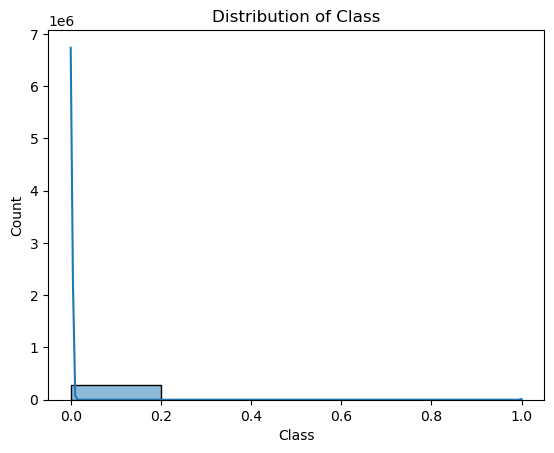

In [17]:
num_features = df.select_dtypes(include=['int64','float64']).columns

for col in num_features:
    sns.histplot(df[col], bins=5, kde=True) 
    plt.title(f"Distribution of {col}")
    plt.show()
# most of V values in negative range (-20 - 5) and some in positive range(0-20)

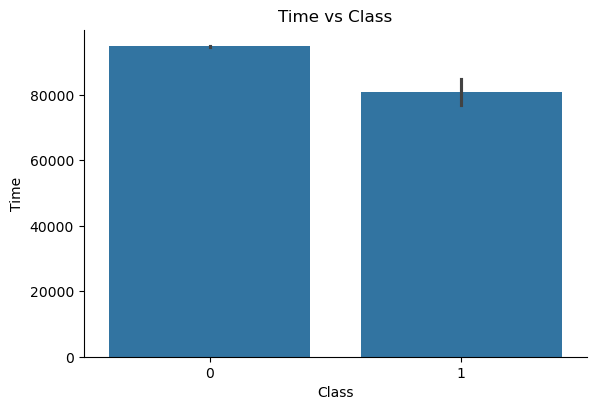

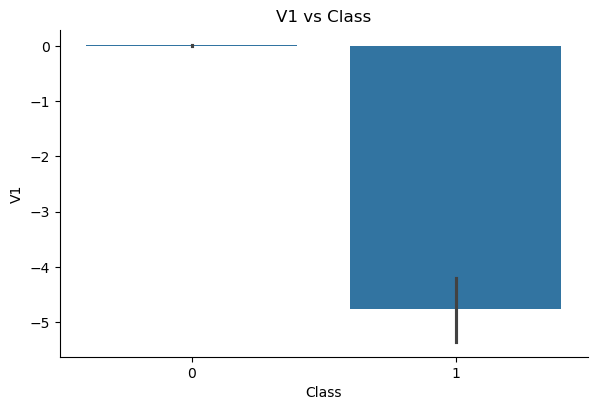

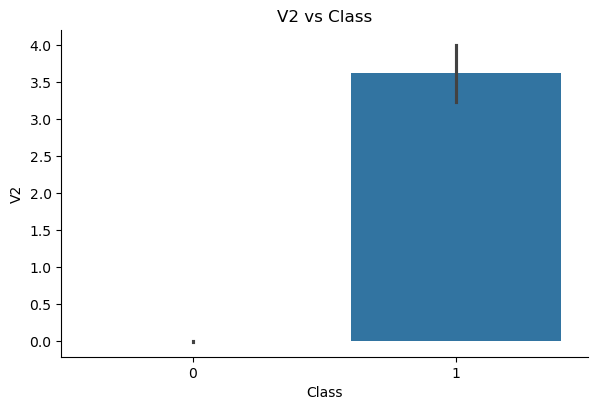

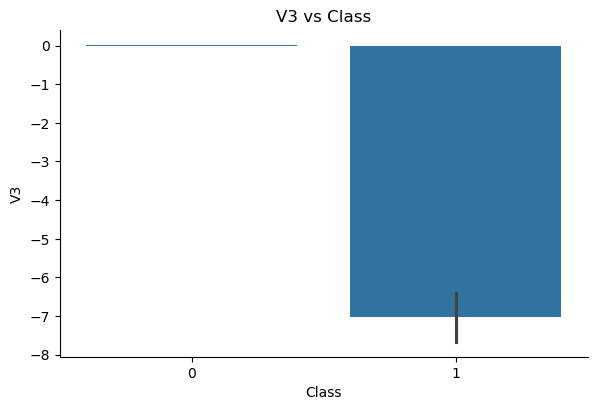

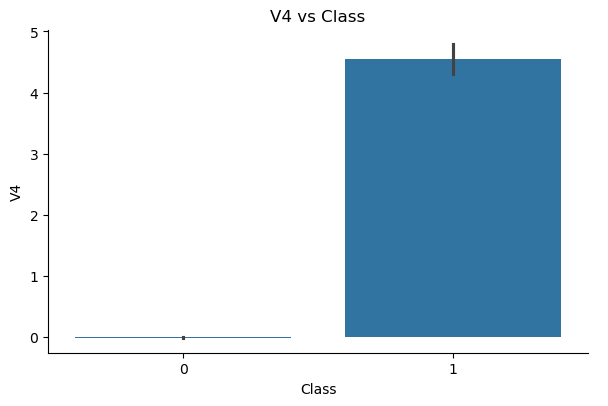

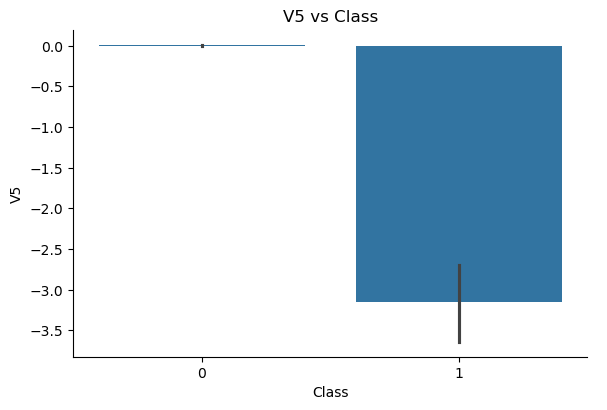

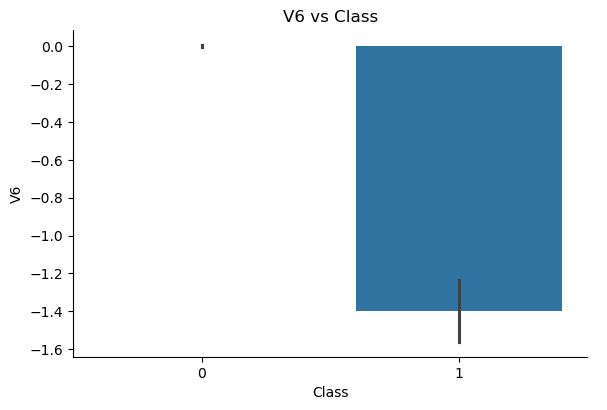

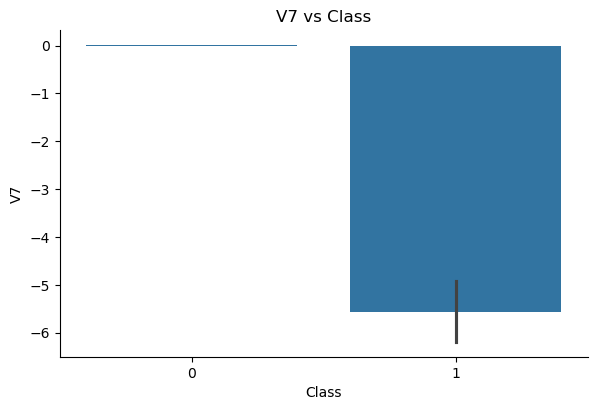

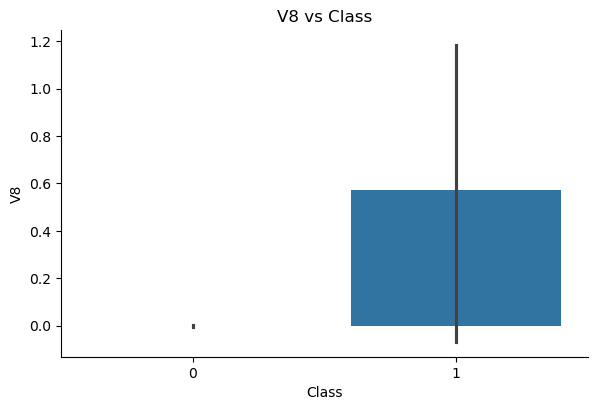

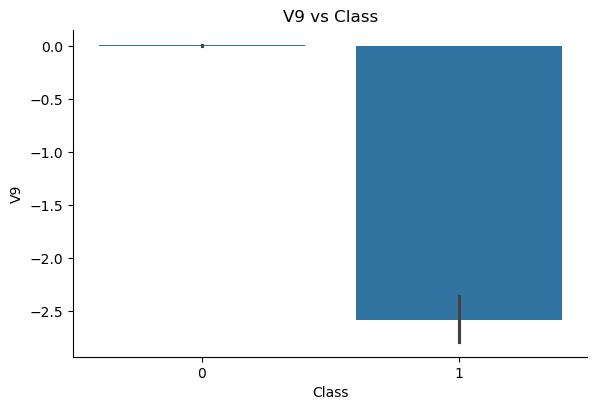

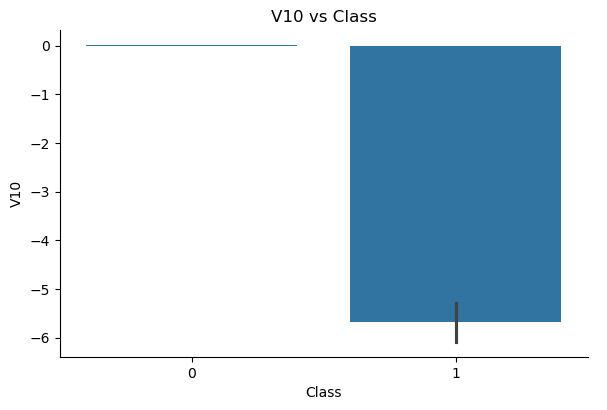

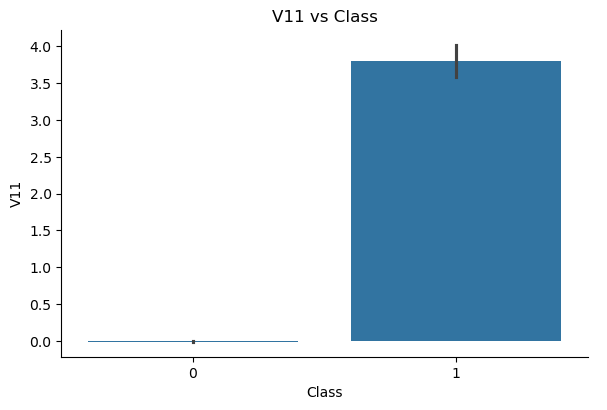

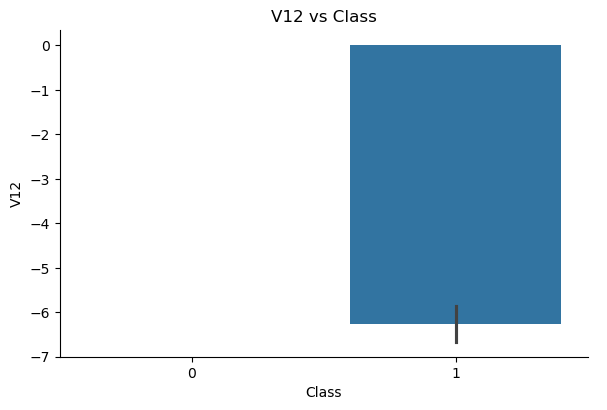

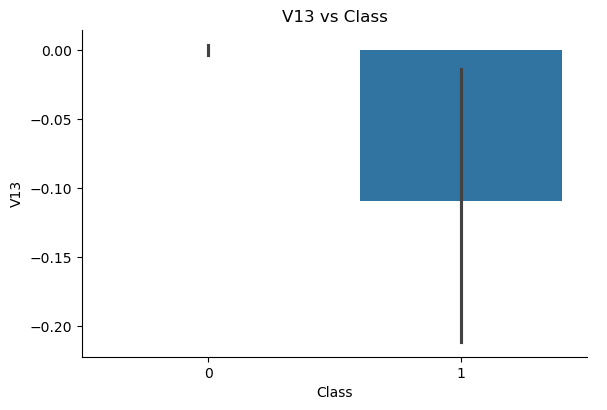

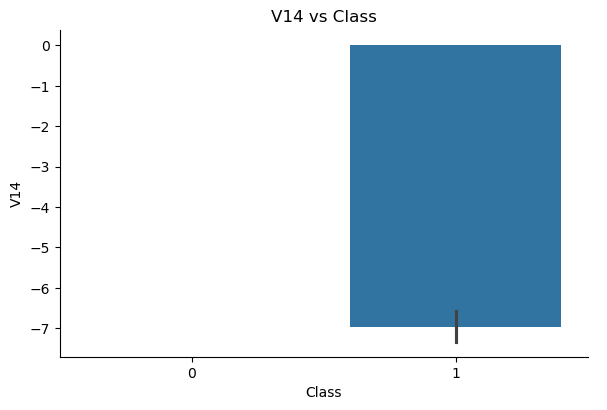

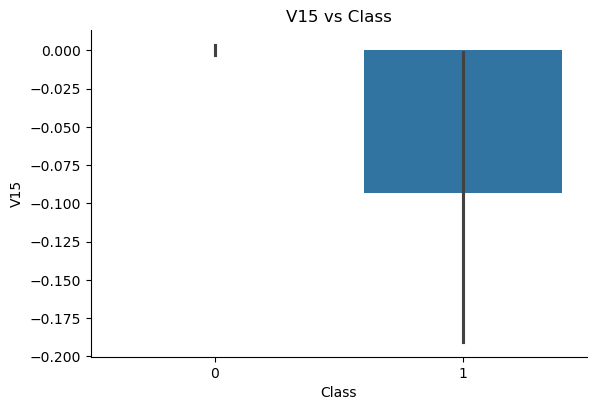

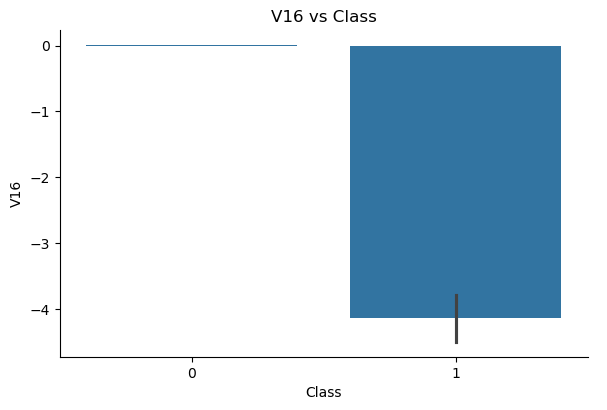

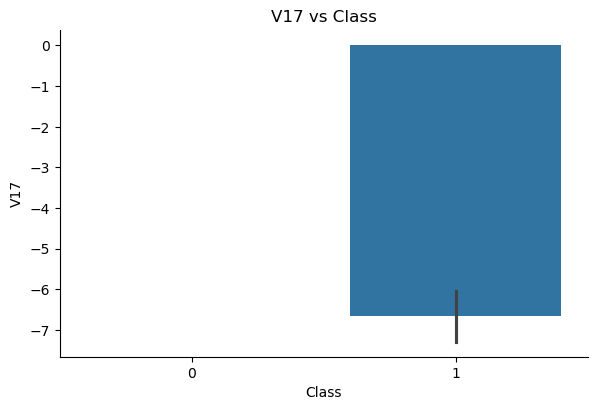

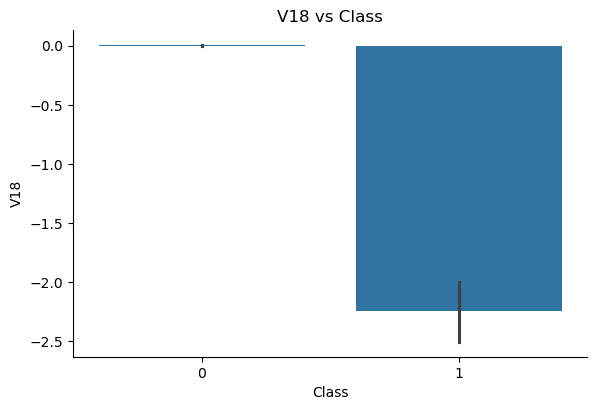

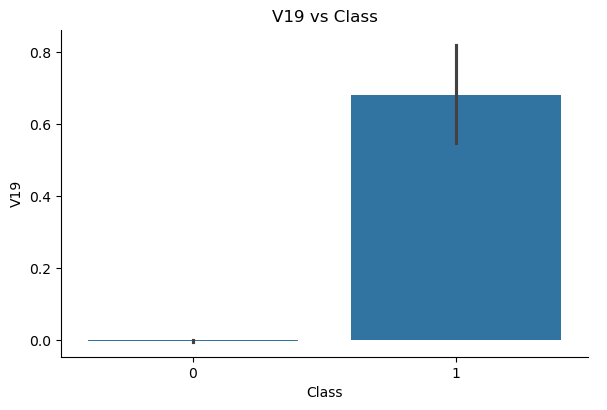

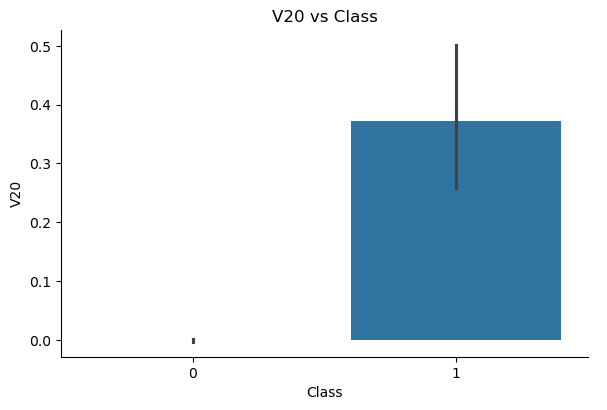

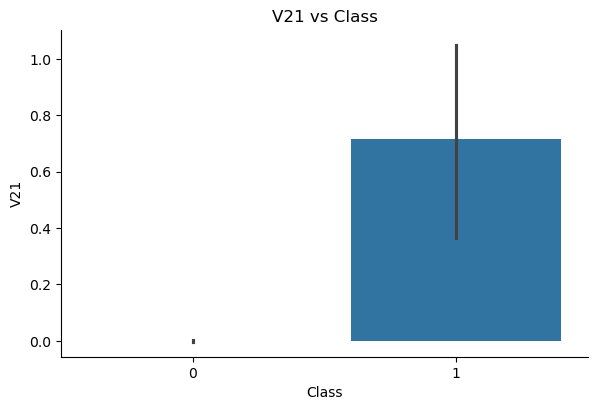

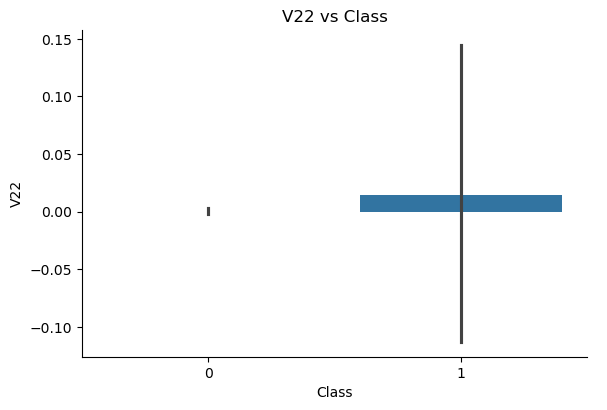

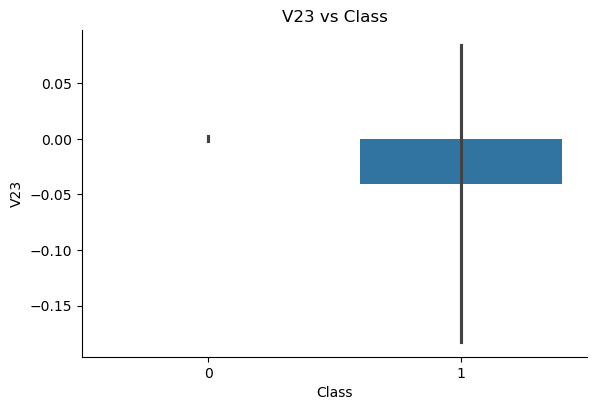

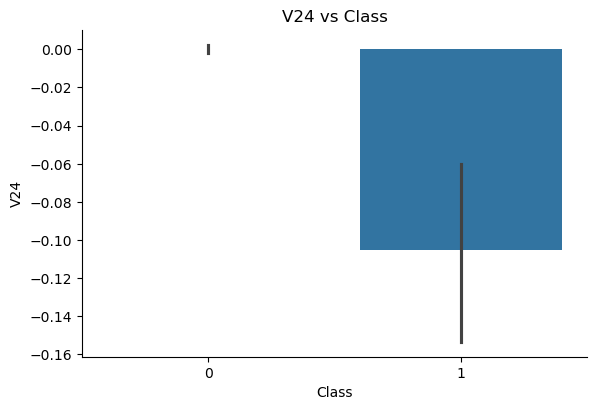

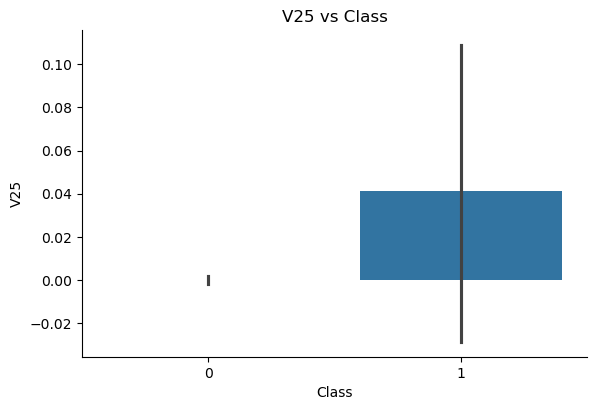

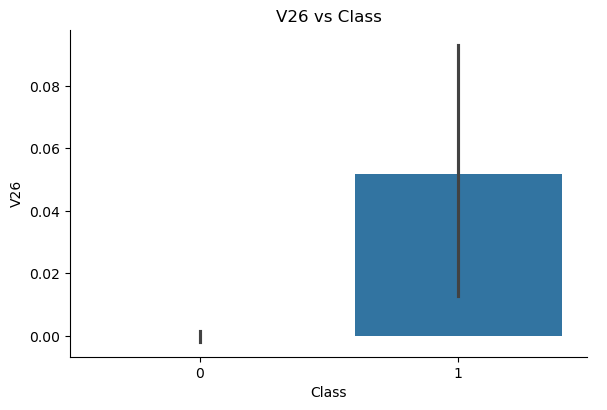

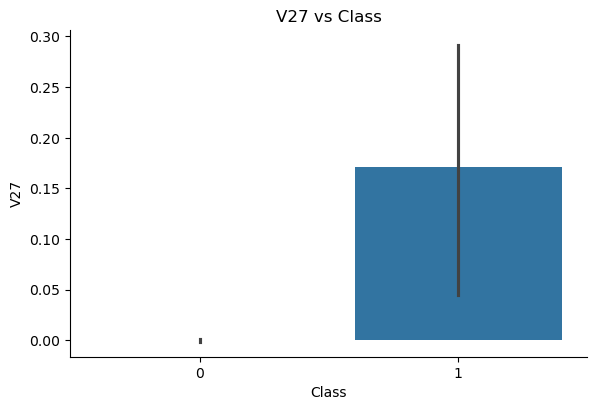

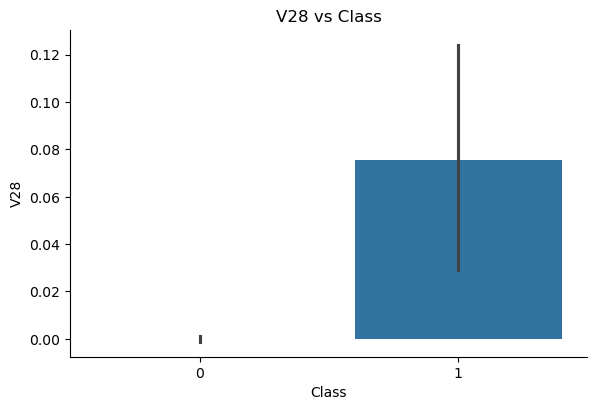

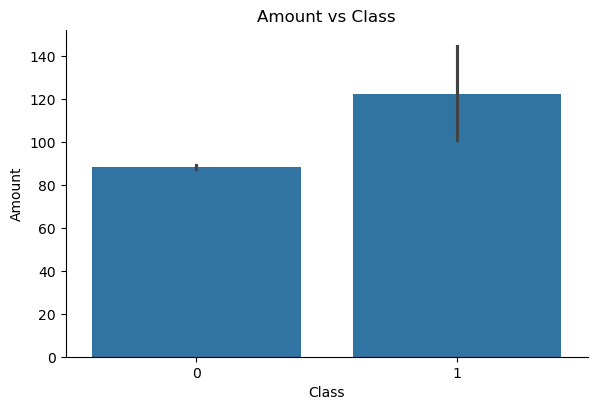

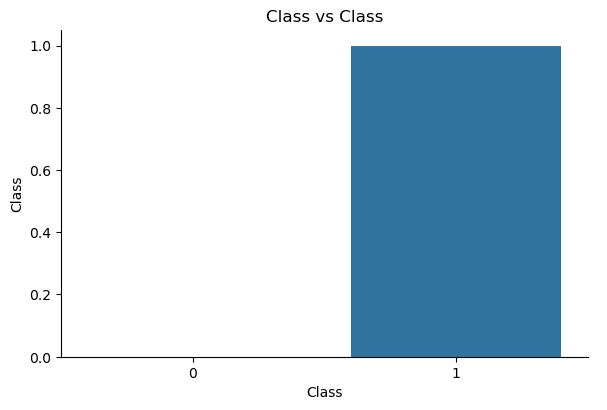

In [18]:
num_features = df.select_dtypes(include=['int64','float64']).columns 
# Loop through each numerical feature and plot against target 
for col in num_features:
    sns.catplot(x='Class', y=col, data=df, kind='bar', height=4, aspect=1.5)
    plt.title(f"{col} vs Class")
    plt.show()

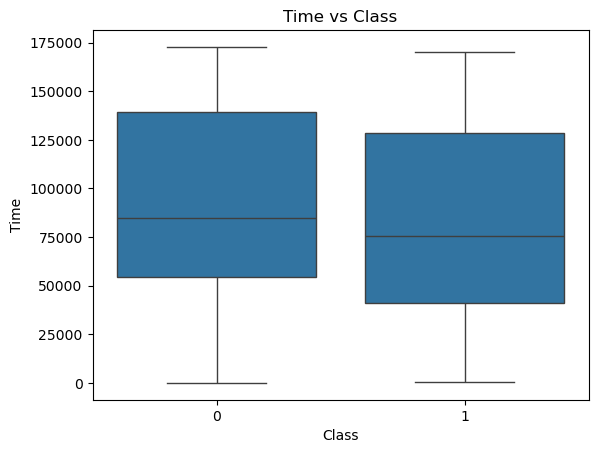

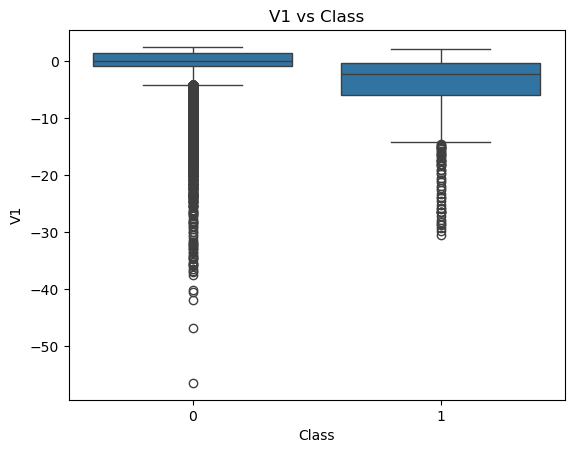

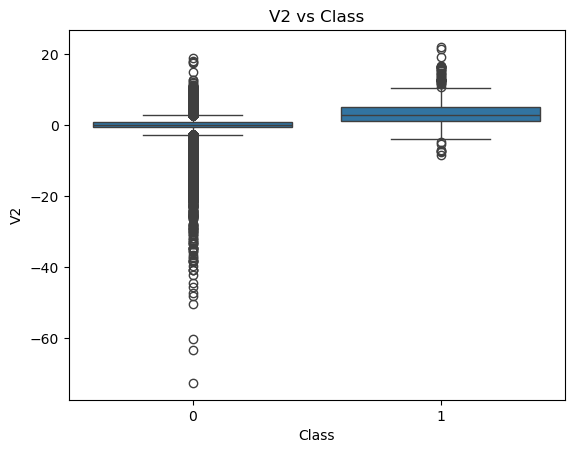

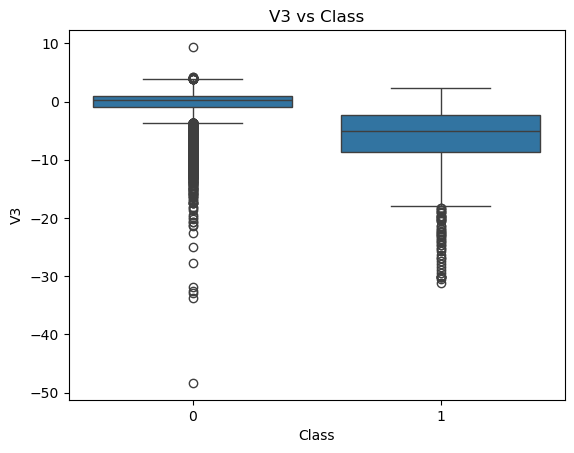

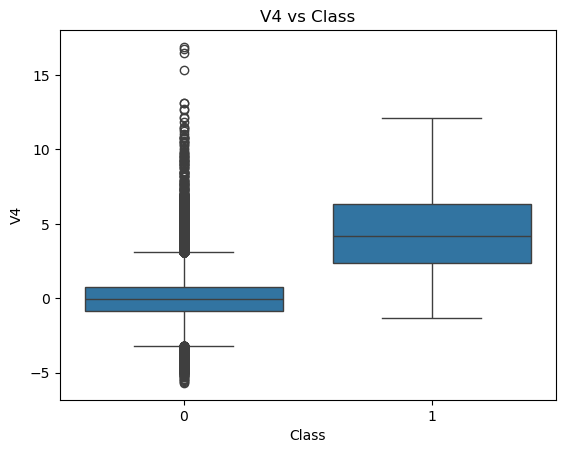

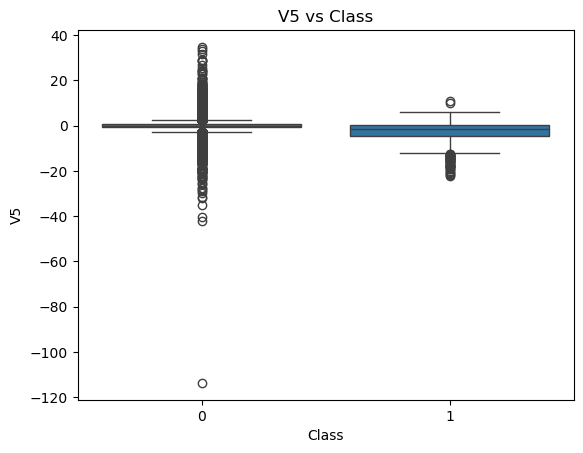

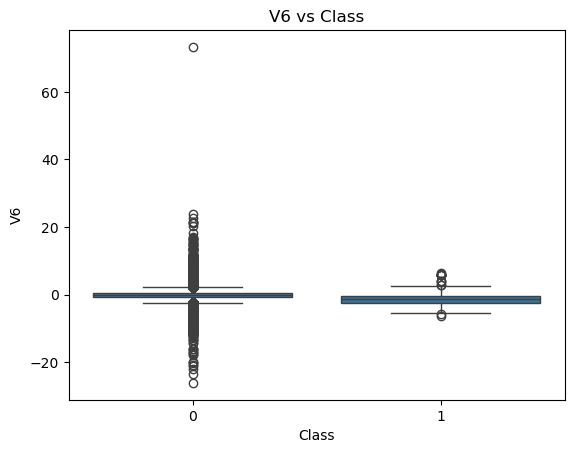

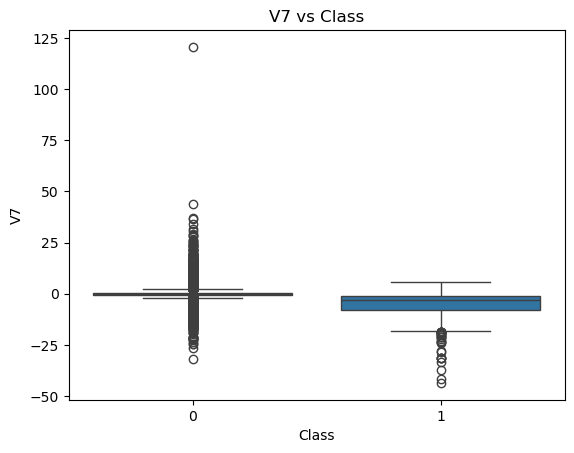

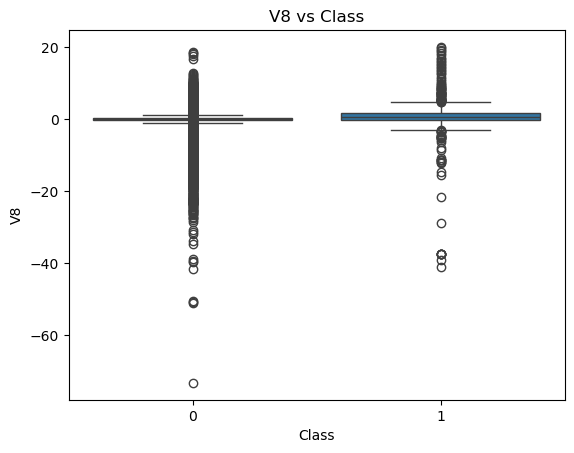

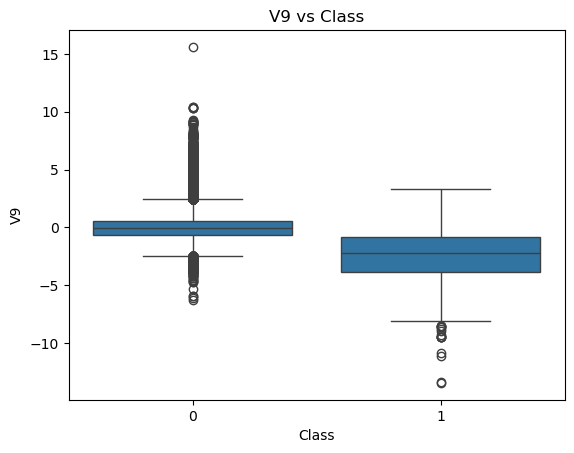

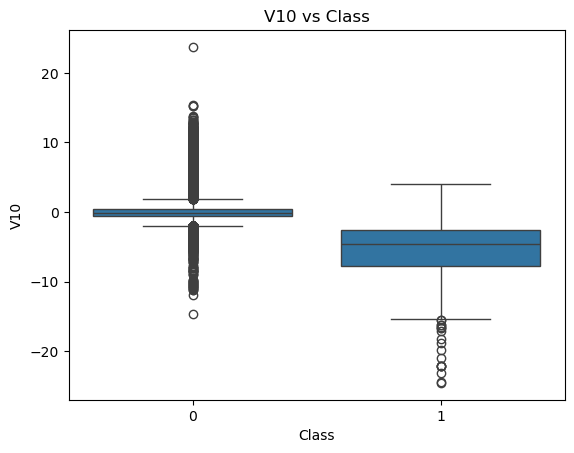

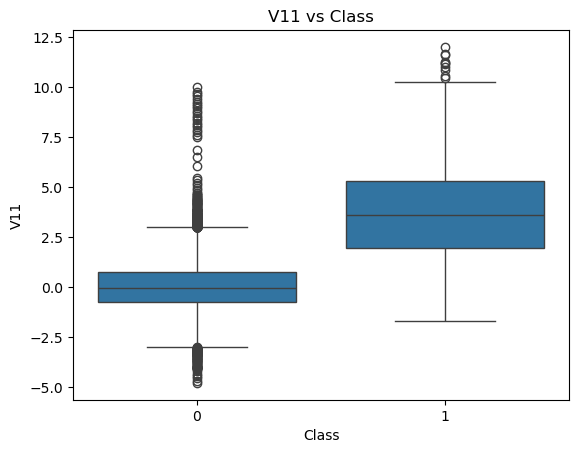

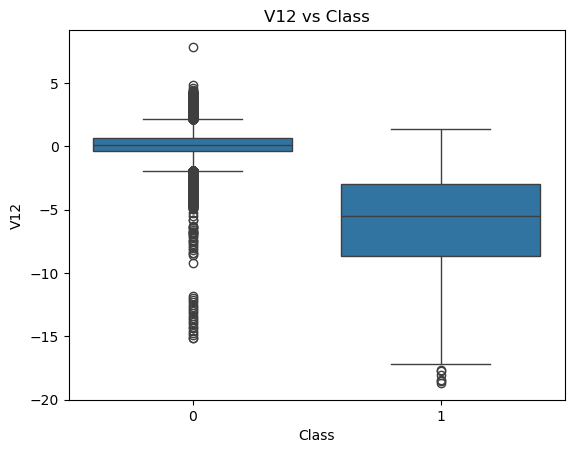

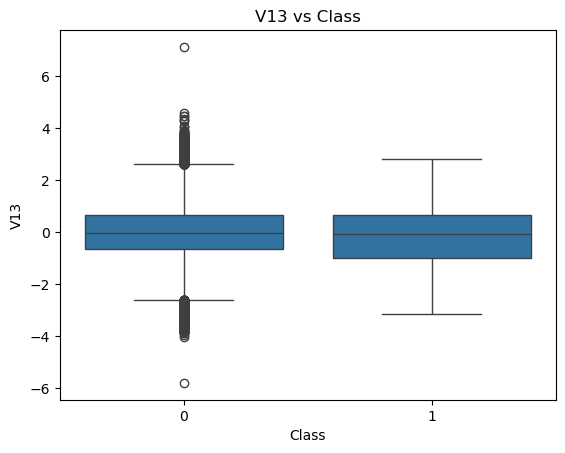

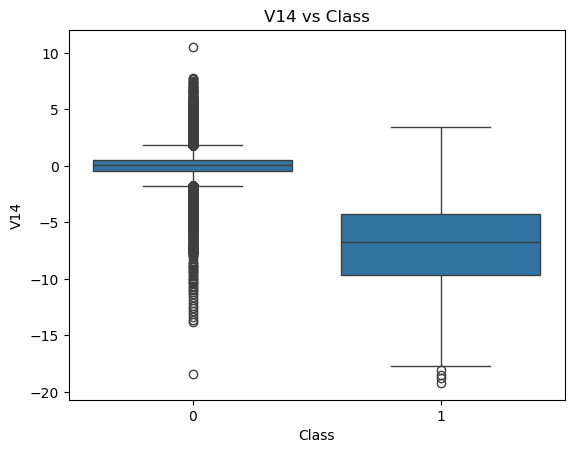

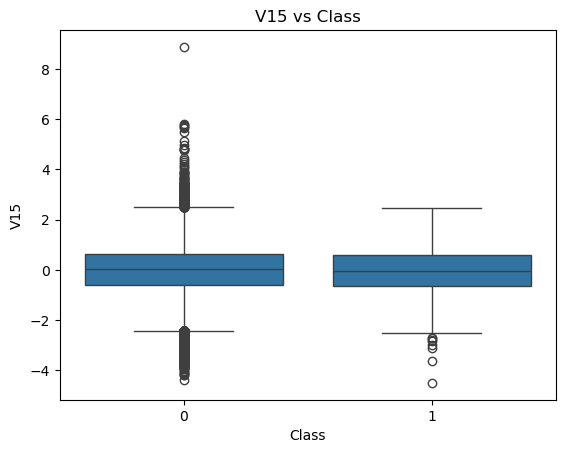

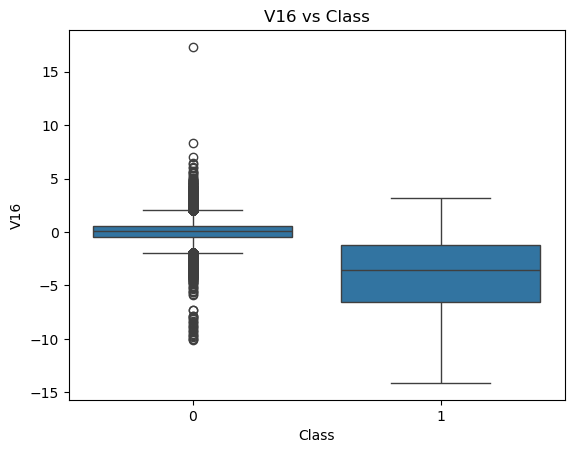

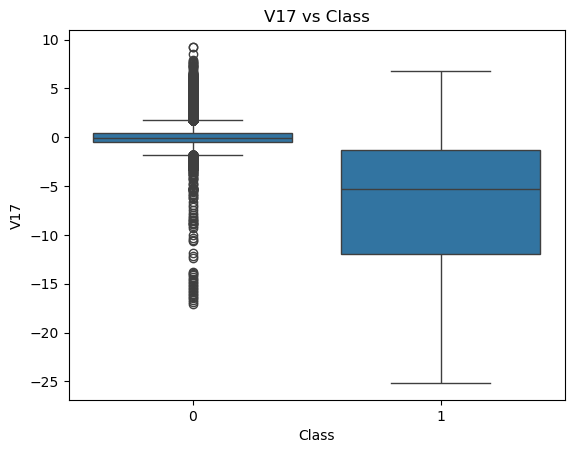

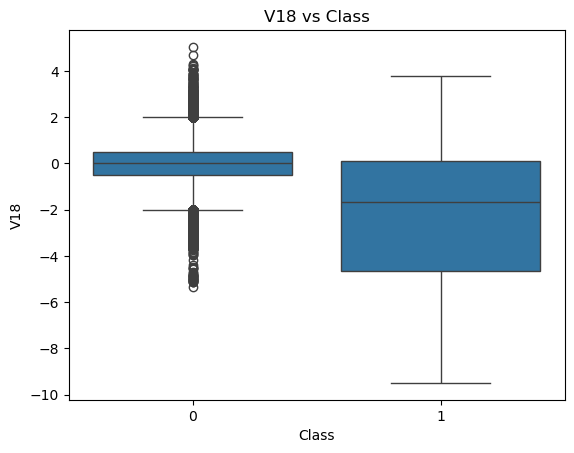

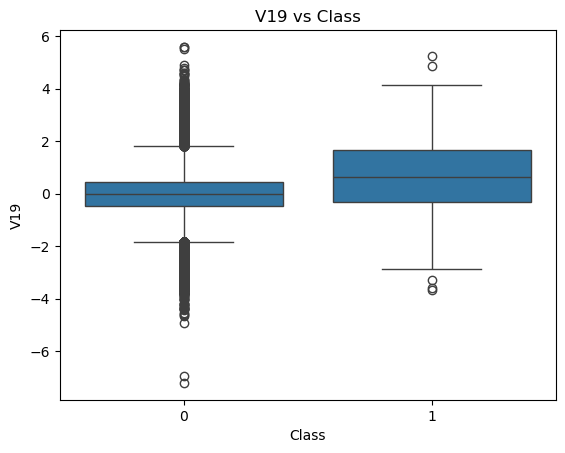

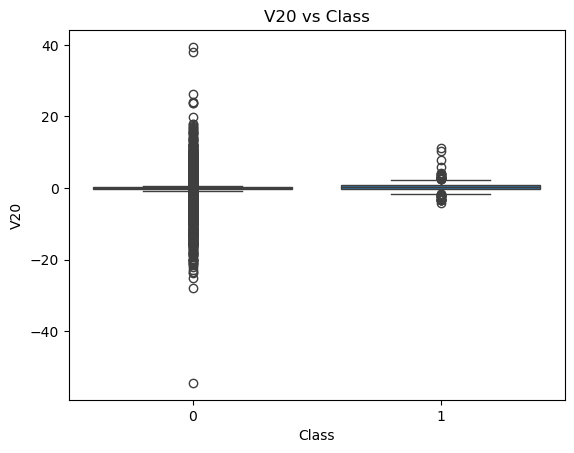

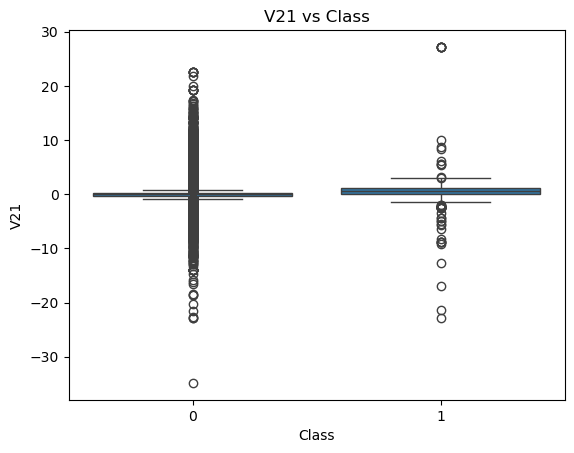

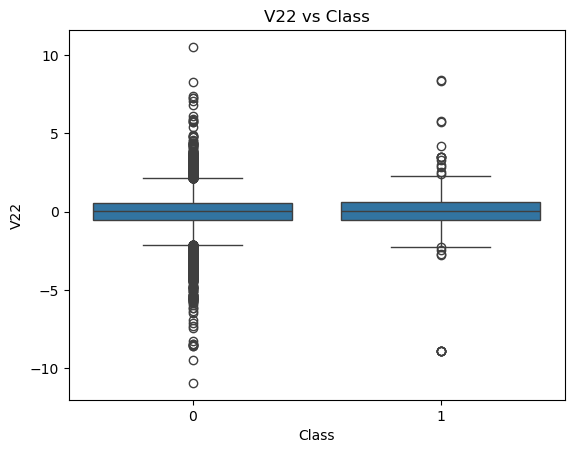

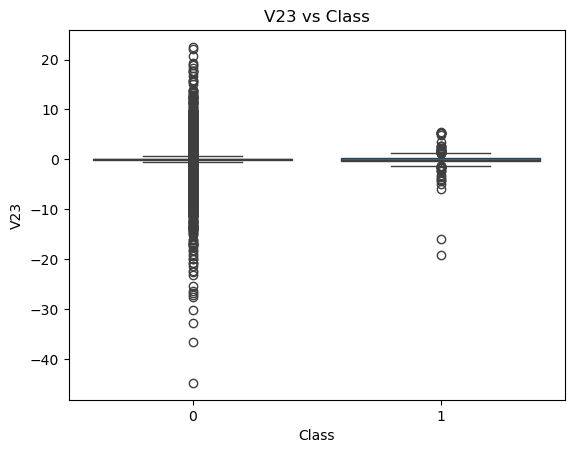

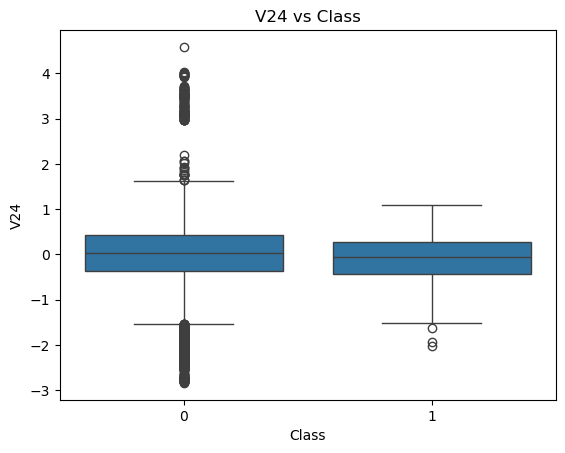

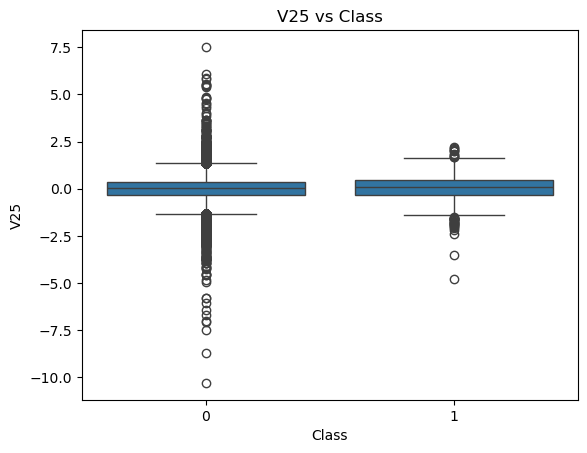

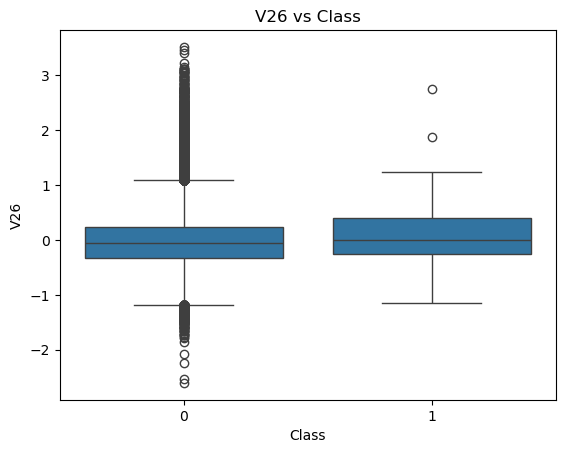

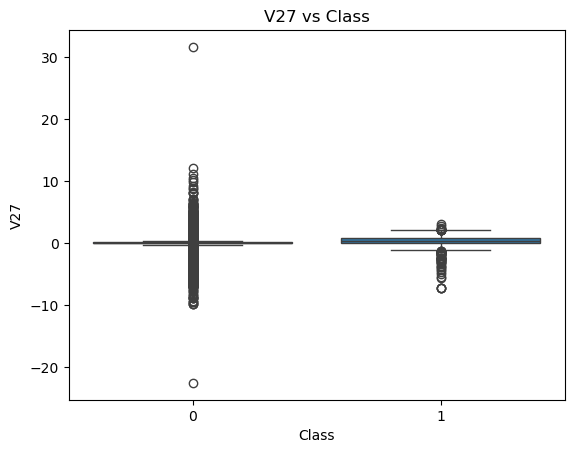

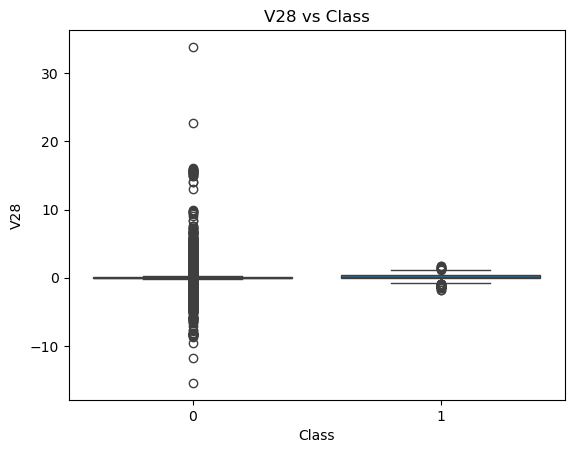

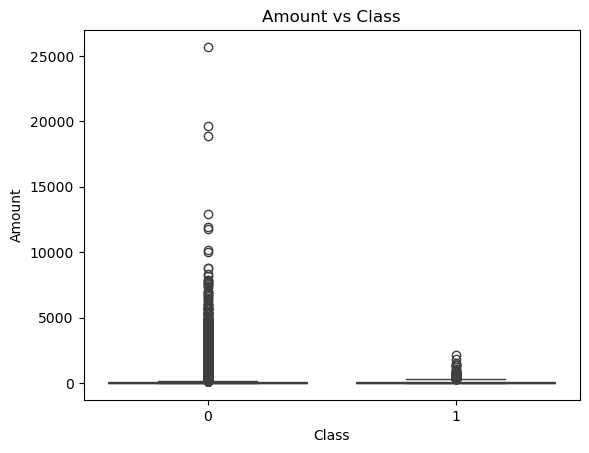

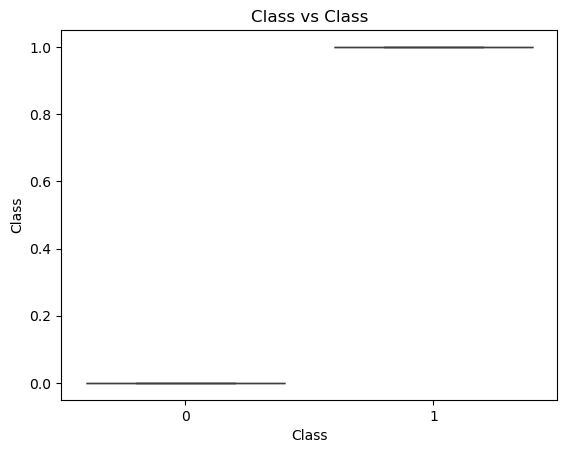

In [19]:
for col in num_features: 
    sns.boxplot(x='Class', y=col, data=df) 
    plt.title(f"{col} vs Class")
    plt.show()
# we see a lot of outliers espacially in V colomns in the case of NotFraude(0)

In [17]:
# Correlation matrix
corr_matrix = df.corr()

# Extract correlation with target
target_corr = corr_matrix['Class'].drop('Class')

# Sort by absolute value but keep the sign
# use abe to leave la negation
sorted_corr = target_corr.sort_values(key=lambda x: x.abs(), ascending=False)

print(sorted_corr)


V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64


In [18]:
import pandas as pd

# Compute correlation matrix
corr_matrix = df.corr()

# Extract correlation with target
target_corr = corr_matrix['Class'].drop('Class')

# Sort from most to least 
sorted_corr = target_corr.sort_values(key=lambda x: x, ascending=False)

print(sorted_corr)


V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


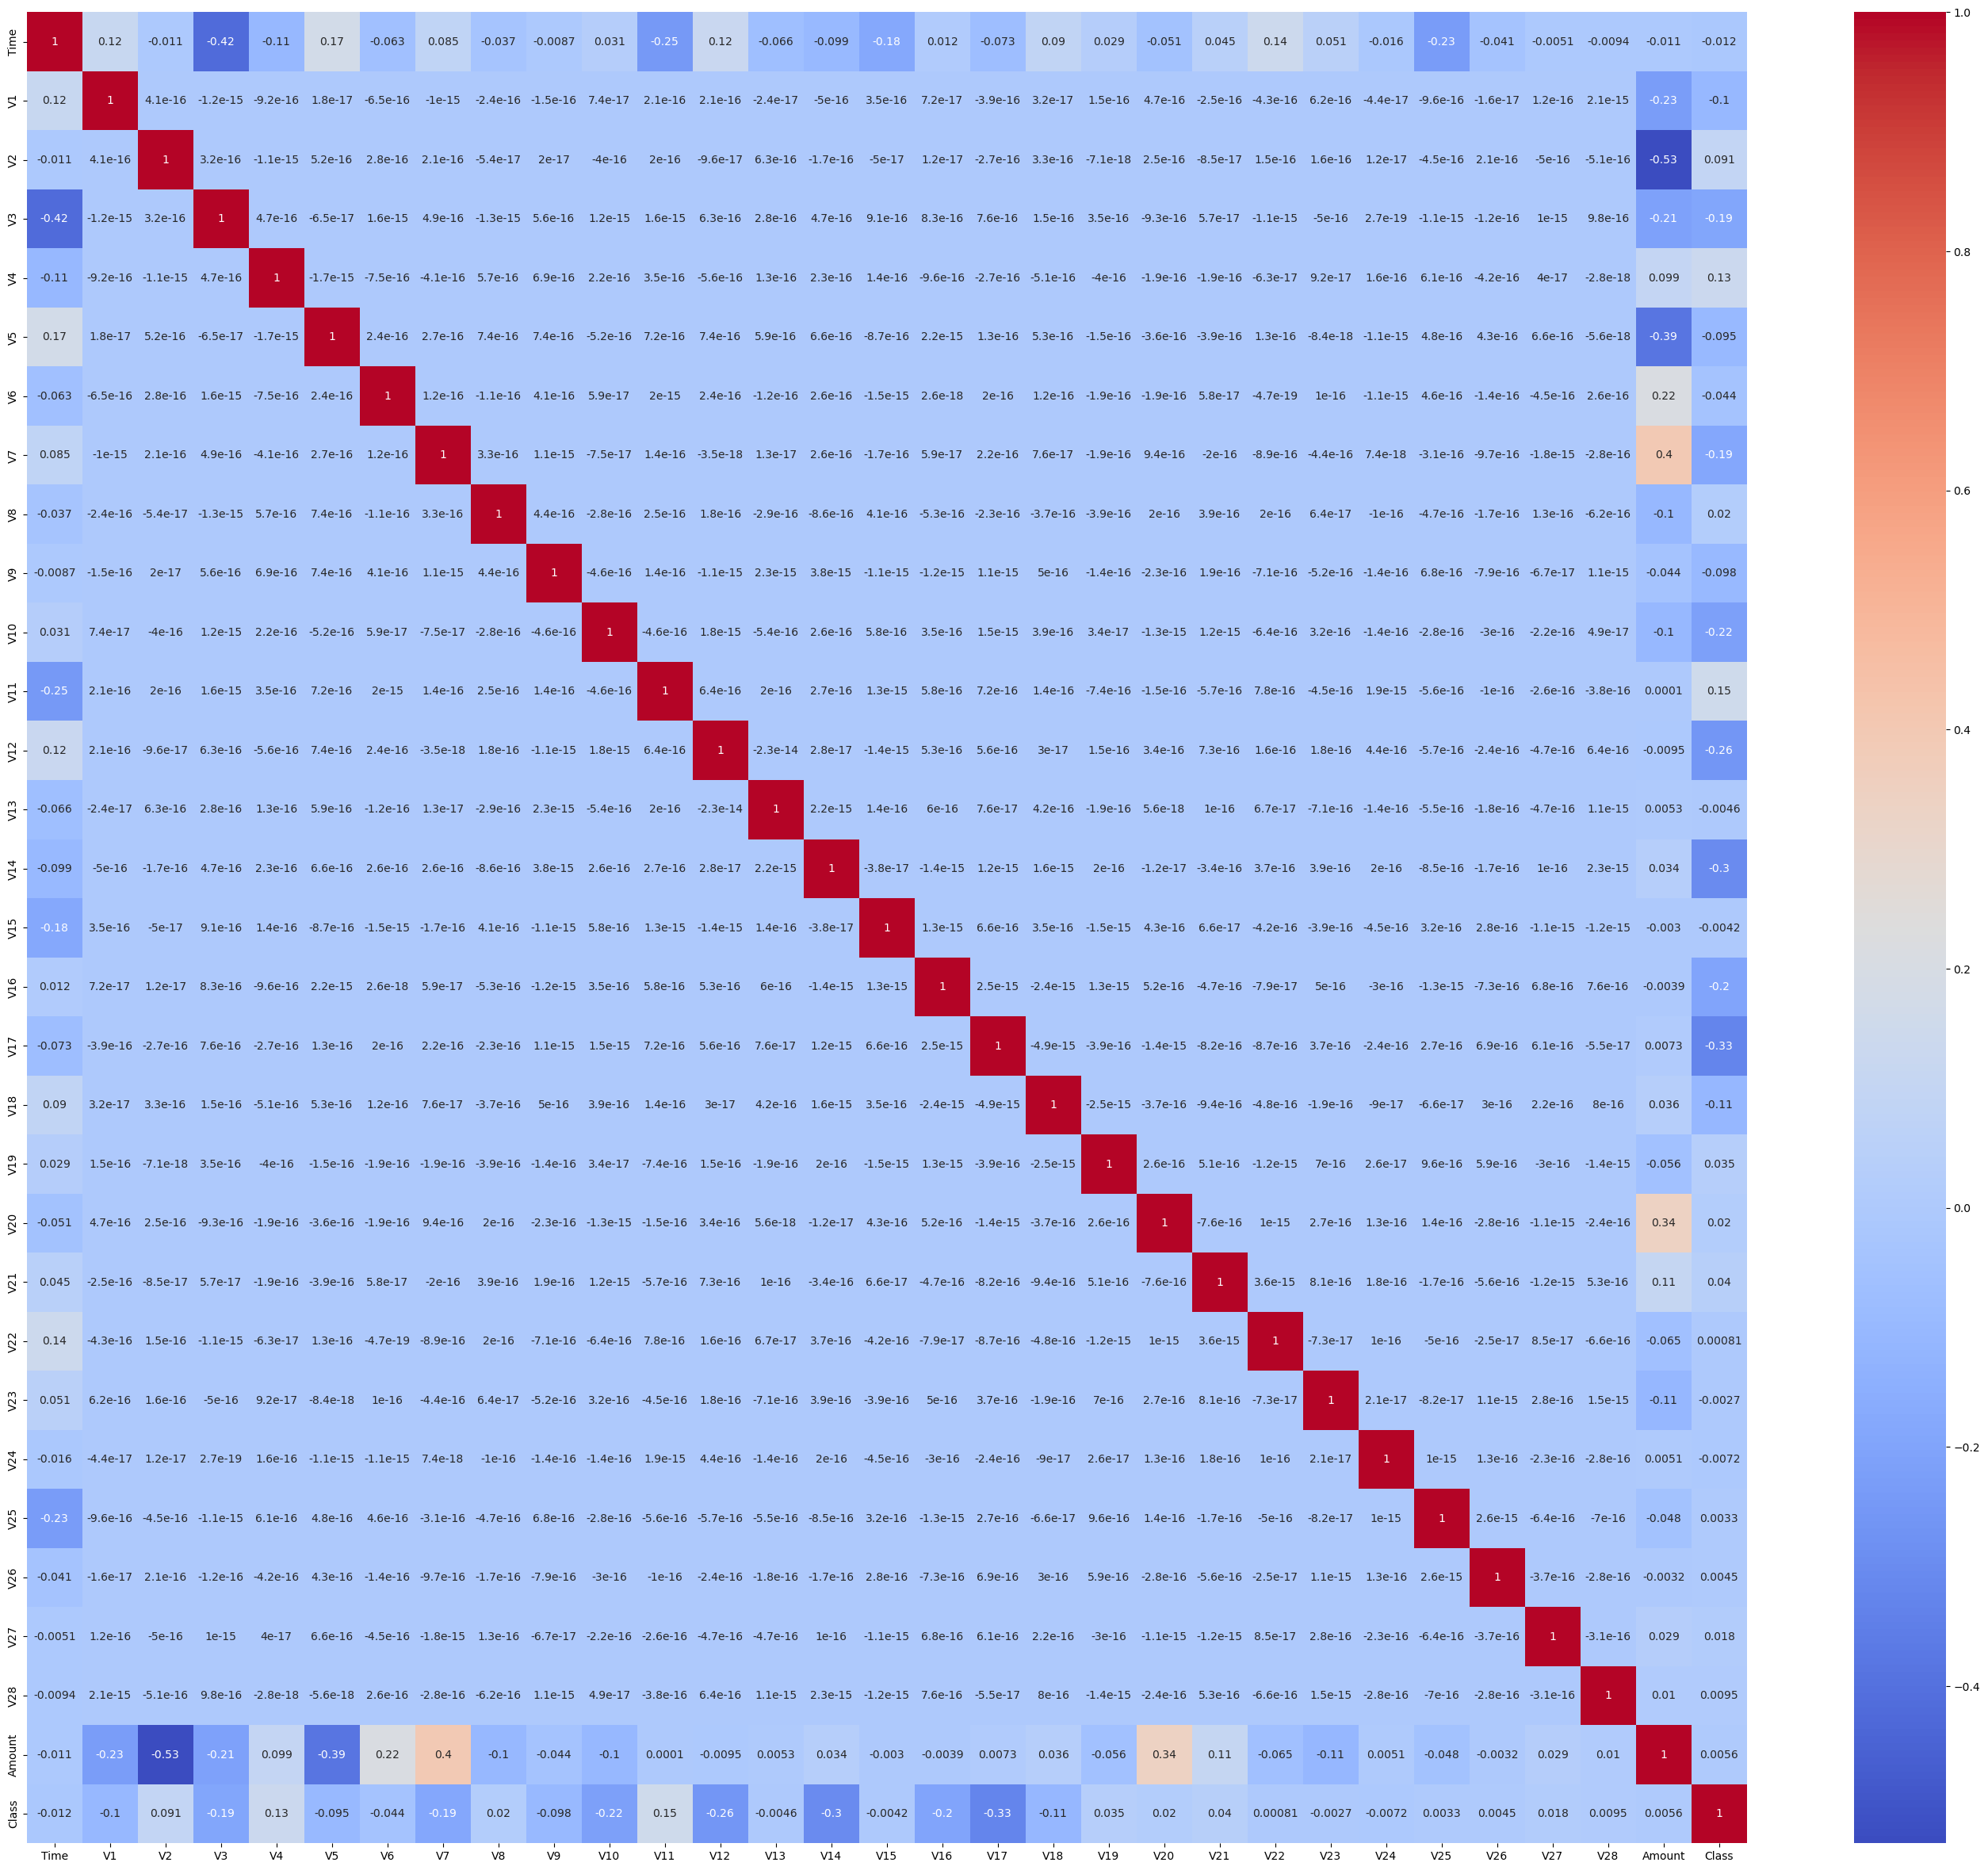

In [19]:
plt.figure(figsize=(35,30))
sns.heatmap(df.corr(), annot=True , cmap='coolwarm')
plt.show()

In [20]:

# Separate numeric columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

# --- Initialize dictionary ---
outlier_counts = {}

# --- Detect outliers using IQR method ---
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    outlier_counts[col] = len(outliers)

# --- Convert to Series and sort ---
outlier_counts = pd.Series(outlier_counts).sort_values(ascending=False)

print(outlier_counts)


V27       39163
Amount    31904
V28       30342
V20       27770
V8        24134
V6        22965
V23       18541
V12       15348
V21       14497
V14       14149
V2        13526
V5        12295
V4        11148
V19       10205
V10        9496
V7         8948
V9         8283
V16        8184
V18        7533
V17        7420
V1         7062
V26        5596
V25        5367
V24        4774
V13        3368
V3         3363
V15        2894
V22        1317
V11         780
Class       492
Time          0
dtype: int64


In [21]:
#elimine non inmportant features with alot of outliers['V1','V3', 'V5', 'V6', 'V7','V9', 'V10','V12', 'V14', 'V16', 'V17', 'V18']

In [22]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [23]:
df = df.drop(['V1','V3', 'V5', 'V6', 'V7','V9', 'V10','V12', 'V14', 'V16', 'V17', 'V18'],axis=1) #elimine non inmportant features with alot of outliers
df.head()

,Time,V2,V4,V8,V11,V13,V15,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-0.072781,1.378155,0.098698,-0.551600,-0.991390,1.468177,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,0.266151,0.448154,0.085102,1.612727,0.489095,0.635558,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.340163,0.379780,0.247676,0.624501,0.717293,2.345865,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.185226,-0.863291,0.377436,-0.226487,0.507757,-0.631418,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,0.877737,0.403034,-0.270533,-0.822843,1.345852,0.175121,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [24]:
df.shape

(284807, 19)

In [25]:
df.columns

Index(['Time', 'V2', 'V4', 'V8', 'V11', 'V13', 'V15', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'],
      dtype='object')

### Pre-processing
is the process of getting our dataset ready for model training. In this section, we will perform the following preprocessing steps:

* Data cleaning (lignes(duplicate/non pertinetes)- colonne(redandance/donnees incorrect/nan/outliers)
* Drop and fill missing values (no used)
* Encoding (no used)
* Data trasformation (log transformation) - suppression outliers
* Feature engineering
* Features Scaling
* Create Train Test set

In [26]:
df.isnull().sum() # no nan

Time      0
V2        0
V4        0
V8        0
V11       0
V13       0
V15       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [27]:
duplicate_lignes = df.duplicated()
duplicate_lignes

0         False
1         False
2         False
3         False
4         False
          ...  
284802    False
284803    False
284804    False
284805    False
284806    False
Length: 284807, dtype: bool

#### Train test split

In [34]:
from sklearn.model_selection import train_test_split

x = df.drop(['Class'],axis=1)
y = df['Class']

x_train , x_test ,y_train, y_test = train_test_split(x,y, test_size=0.25 , random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(213605, 18)
(71202, 18)
(213605,)
(71202,)


#### handling outliers (Robust Scaling + Transformation (Excellent for Fraud Detection))

In [35]:
from sklearn.preprocessing import RobustScaler

# 1. Fit RobustScaler ONLY on training data
scaler = RobustScaler()
x_train_scaled = scaler.fit_transform(x_train)  # Fit on train only

# 2. Transform test data with the SAME scaler
x_test_scaled = scaler.transform(x_test)        # Don't fit on test!

# 3. Convert back to DataFrames (optional)
x_train_scaled_df = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns=x_test.columns)

print(" Outliers handled for ALL columns!")
print(f"x_train scaled shape: {x_train_scaled.shape}")
print(f"x_test scaled shape: {x_test_scaled.shape}")

✅ Outliers handled for ALL columns!
x_train scaled shape: (213605, 18)
x_test scaled shape: (71202, 18)


#### feature scalling (make it in same echelle)
* Normalization (Min-Max) =>This rescales values into a fixed range, usually [0,1].
* Standardization (Z-score Scaling)=>This rescales values so that each feature has mean = 0 and standard deviation = 1.

how to choose :

*If your features have different ranges but are bounded, use Normalization.
* If your features have different distributions or unbounded values, use Standardization.
* If unsure, start with Standardization — it’s more robust in practice.

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_sc = scaler.fit_transform(x_train_scaled)

x_test= scaler.transform(x_test_scaled)

## Modelling 

In [37]:
# model 1 : Logistic Regression

In [39]:
from sklearn.linear_model import LogisticRegression

lr =LogisticRegression() # Build model
lr.fit(x_train_sc,y_train) # training 
y_pred = lr.predict(x_test) # evalute 

from sklearn.metrics import accuracy_score

accuracy_score_lr =accuracy_score(y_test,y_pred)
print('accuracy_score_lr',accuracy_score_lr) # its perfect score wow !! 99%

accuracy_score_lr 0.9989887924496503


confusion_matrix_lr [[71076    13]
 [   59    54]]


<Axes: >

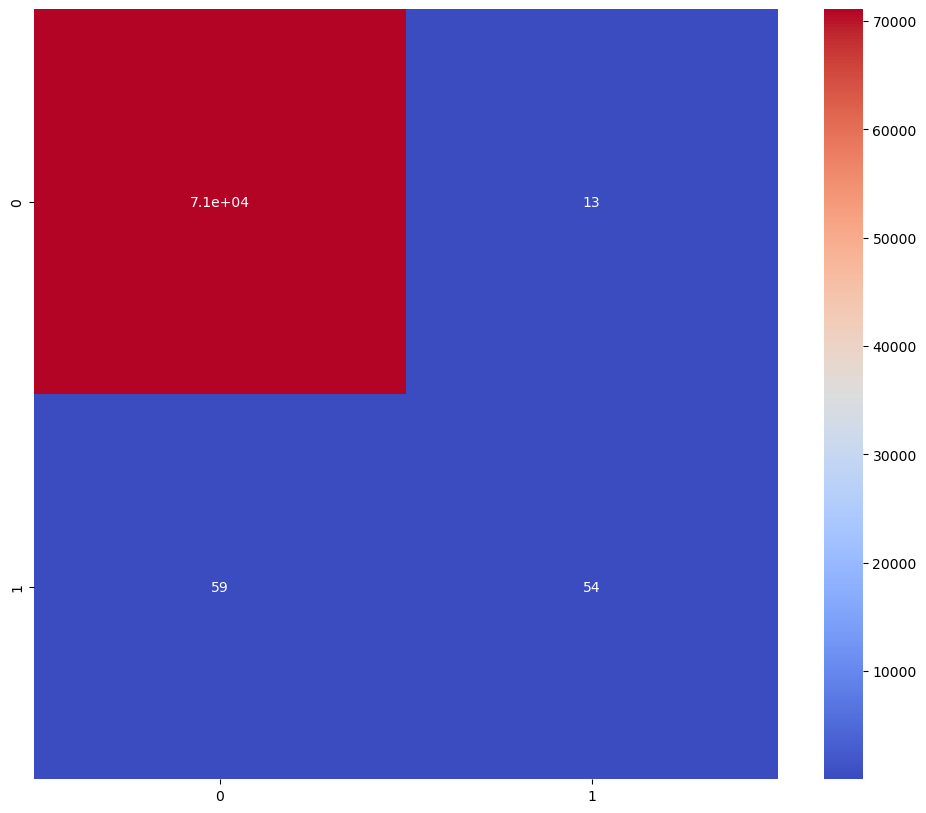

In [42]:
from sklearn.metrics import confusion_matrix

confusion_matrix_lr=confusion_matrix(y_test,y_pred)
print('confusion_matrix_lr',confusion_matrix_lr)

#visualisation de matrice de confusion
plt.figure(figsize=(12,10))
sns.heatmap(confusion_matrix_lr,annot=True , cmap='coolwarm') 

In [43]:
# model 2 : descion tree 

accuracy_score_dtc 0.9719670795764164
confusion_matrix_dtc [[69110  1979]
 [   17    96]]


<Axes: >

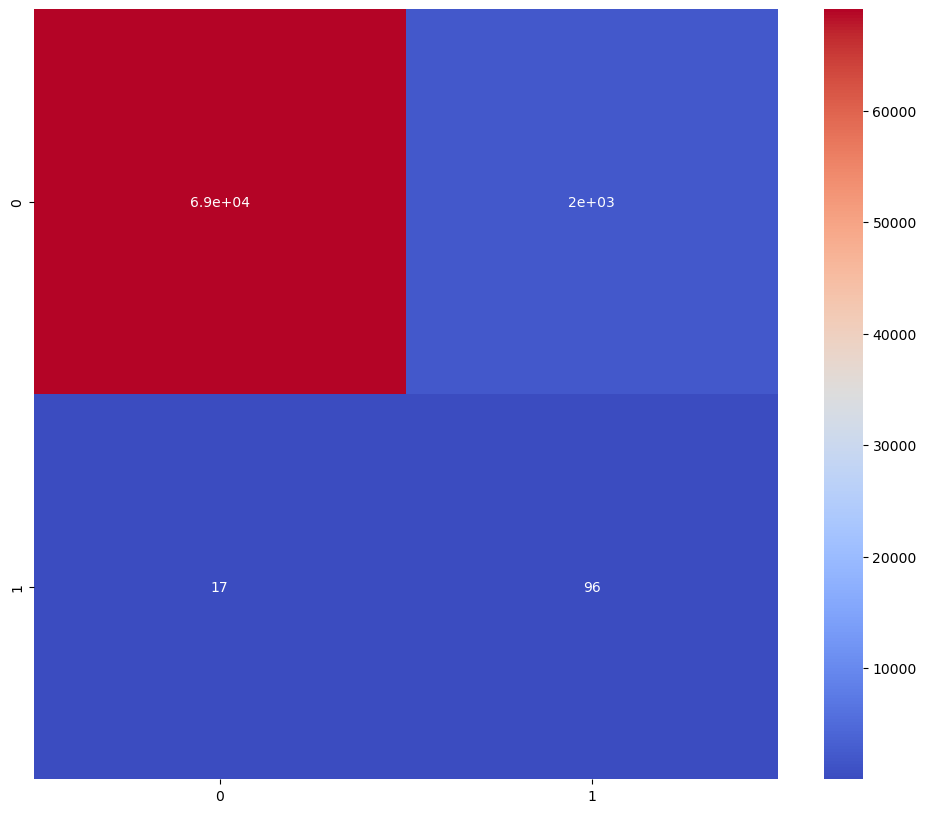

In [44]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,           # Prevent overfitting
    min_samples_split=20,  # Prevent overfitting
    class_weight='balanced'  # Important for imbalanced fraud data!
)

dtc.fit(x_train_sc,y_train)
y_pred_dtc = dtc.predict(x_test)

accuracy_score_dtc = accuracy_score(y_test,y_pred_dtc)
print('accuracy_score_dtc',accuracy_score_dtc) # good score tho with 97%

confusion_matrix_dtc=confusion_matrix(y_test,y_pred_dtc)
print('confusion_matrix_dtc',confusion_matrix_dtc)

#visualisation de matrice de confusion
plt.figure(figsize=(12,10))
sns.heatmap(confusion_matrix_dtc,annot=True , cmap='coolwarm') 

In [ ]:
# model : KNN

accuracy_score_knn 0.9991432824920649
confusion_matrix_knn [[71085     4]
 [   57    56]]


<Axes: >

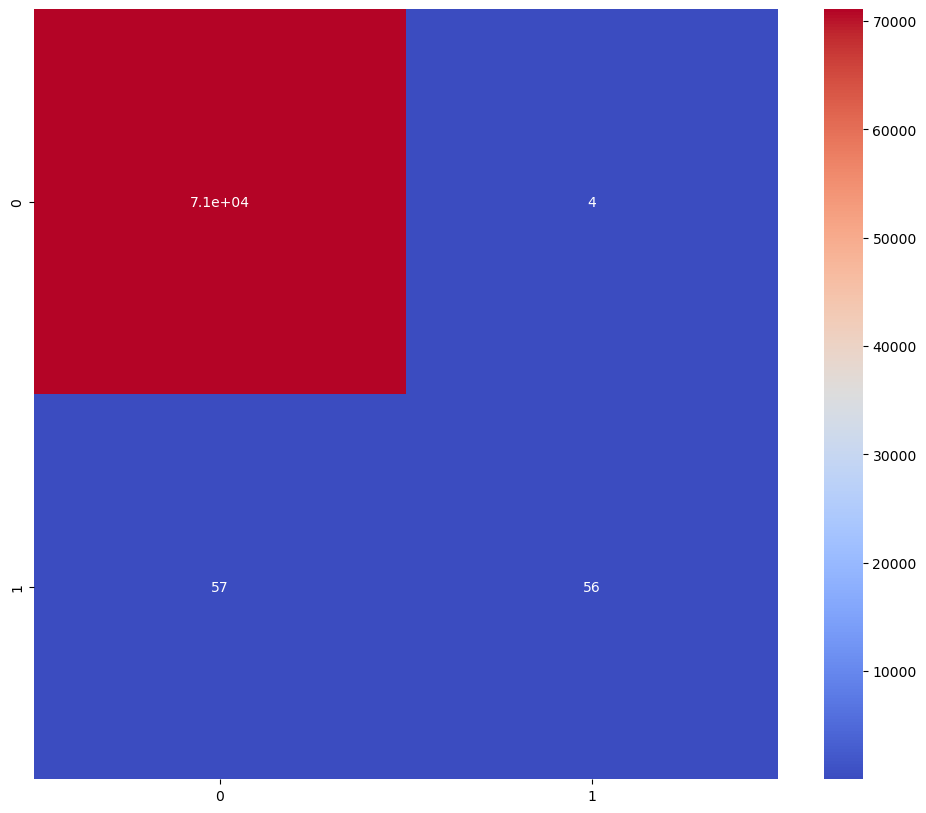

In [45]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,        # Start with 5 neighbors
    weights='distance',    # Closer neighbors have more weight
    metric='minkowski',    # Default distance metric
    p=2                    # Euclidean distance (p=2)
)

knn.fit(x_train_sc , y_train)

y_pred_knn =knn.predict(x_test)

accuracy_score_knn = accuracy_score(y_test,y_pred_knn)
print('accuracy_score_knn',accuracy_score_knn) # sublime score tho with 99,9%

confusion_matrix_knn=confusion_matrix(y_test,y_pred_knn)
print('confusion_matrix_knn',confusion_matrix_knn)

#visualisation de matrice de confusion
plt.figure(figsize=(12,10))
sns.heatmap(confusion_matrix_knn,annot=True , cmap='coolwarm') 

### Test our models

In [48]:
# save model
import joblib

# Save model and scaler
joblib.dump(knn, 'fraud_knn_model.pkl')
joblib.dump(scaler, 'fraud_scaler.pkl')

# Also save the feature columns for reference
feature_cols = ['Time', 'V2', 'V4', 'V8', 'V11', 'V13', 'V15', 'V19', 'V20', 'V21',
                'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

joblib.dump(feature_cols, 'feature_columns.pkl')
print("✅ Model, scaler, and feature columns saved!")

✅ Model, scaler, and feature columns saved!


In [50]:
## Test on new data
# Test single transaction (simple)
sample_idx = 0  # Change this index to test different transactions

single_tx = x_test_scaled[sample_idx:sample_idx+1]
prediction = model.predict(single_tx)[0]
probability = model.predict_proba(single_tx)[:, 1][0]
actual_label = y_test.iloc[sample_idx]

print(f"🔍 Transaction Test Results:")
print(f"Prediction: {'FRAUD' if prediction == 1 else 'LEGIT'}")
print(f"Fraud Probability: {probability*100:.2f}%")
print(f"Actual Label: {'FRAUD' if actual_label == 1 else 'LEGIT'}")
print(f"Correct: {'✅ YES' if prediction == actual_label else '❌ NO'}")

🔍 Transaction Test Results:
Prediction: FRAUD
Fraud Probability: 100.00%
Actual Label: FRAUD
Correct: ✅ YES


##### as u can see even in new exemple of data it gives good prediction (yay :) )

# Conclusion:

we got a wonderful scores of each model we used:
* KNN => 99,9%
* Logisitic Regression => 99%
* Descion tree => 97%